# Imports

## Import the folder for compatibility (if running local)

In [1]:
import os
import sys

current_dir = os.path.dirname(os.path.abspath("Incremental-Learning-MycroftMinds"))
parent_dir = os.path.dirname(current_dir)
# Insert the parent directory at the beginning of sys.path if it's not already there.
if parent_dir not in sys.path:
    sys.path.insert(0, parent_dir)

## Import external libs and internal models

In [2]:
import time
from typing import Optional, Tuple, Dict, Any, List

from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from river.forest import ARFRegressor
#from river.ensemble import BaggingRegressor, SRPRegressor
from river.tree import HoeffdingTreeRegressor, HoeffdingAdaptiveTreeRegressor
#from river.drift.binary import DDM, EDDM
from src.bagging import ARFRegressorFODT
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.notebook import tqdm

from src.data.io import load_dataset
from src.utils.memory import calculate_memory_usage
from src.utils.utils import get_device_data
from src.trees import fastodt
from src.boosting import IncubationBoost
from src.ensemble_methods import elasticGBDT
from src.evaluation.metrics import calculate_metrics, all_time_aggregation_metrics
from src.evaluation.visualization import plot_part_predictions, plot_hourly_predictions
from src.evaluation.training import all_valid_splits_seq_fit_predict, test_set_seq_fit_predict
from src.evaluation.baseline import PreviousValueRegressor

import ipywidgets as widgets
widgets.IntSlider()

IntSlider(value=0)

# Download the splitted data

In [3]:
# check you data dir and file prefixes
data_dir = '../data/first_batch'

## Pick the hourly or 5-min granularity data
- WFV, train+=28 (train set increasing), validation=28, hourly granularity
- WFV, train+=28 (train set increasing), validation=28, 5-min granularity

In [4]:
HOURLY = True
DATA_FREQUENCY = 'H' if HOURLY else '5min'

In [5]:
# Measure loading time
start_time = time.time()

# Load data
if HOURLY:
    train, valid, test = load_dataset(data_dir=data_dir, prefix='dev_4_hourly_wfv', use_numpy=True)
    features = ['time', 'device_id', 'hour', 'weekday', 'month', 
                 'L1_act_power_lag_1h', 'L1_act_power_lag_24h', 'L1_app_power_lag_1h', 'L1_app_power_lag_24h', 
                 'L1_current_lag_1h', 'L1_current_lag_24h', 'L1_react_power_lag_1h', 'L1_react_power_lag_24h', 
                 'L1_voltage_lag_1h', 'L1_voltage_lag_24h', 
                 'L2_act_power_lag_1h', 'L2_act_power_lag_24h', 'L2_app_power_lag_1h', 'L2_app_power_lag_24h', 
                 'L2_current_lag_1h', 'L2_current_lag_24h', 'L2_react_power_lag_1h', 'L2_react_power_lag_24h', 
                 'L2_voltage_lag_1h', 'L2_voltage_lag_24h', 
                 'L3_act_power_lag_1h', 'L3_act_power_lag_24h', 'L3_app_power_lag_1h', 'L3_app_power_lag_24h', 
                 'L3_current_lag_1h', 'L3_current_lag_24h', 'L3_react_power_lag_1h', 'L3_react_power_lag_24h', 
                 'L3_voltage_lag_1h', 'L3_voltage_lag_24h', 
                 'grid_freq_lag_1h', 'grid_freq_lag_24h', 
                 'powerfactor1_lag_1h', 'powerfactor1_lag_24h', 
                 'powerfactor2_lag_1h', 'powerfactor2_lag_24h', 
                 'powerfactor3_lag_1h', 'powerfactor3_lag_24h']
else:
    train, valid, test = load_dataset(data_dir=data_dir, prefix='8_dev_5_min_wfv', use_numpy=True)
    # copy features from dataloader printouts
    features = []

loading_time = time.time() - start_time
print(f"Data loaded in {loading_time/60:.2f} minutes")

[INFO] Loading train data...
[INFO] Train data loaded: 7 samples
[INFO] Loading valid data...
[INFO] Valid data loaded: 7 samples
[INFO] Loading test data...
[INFO] Test data loaded: 2 samples
Data loaded in 0.00 minutes


## Data structure information

The data structure is as follows:
- For walk-forward validation:
  - `train` is a list of tuples, where each tuple is (X, y) for one split
  - `valid` is a list of tuples, where each tuple is (X, y) for one split
  - `test` is a tuple of (X, y)
- Each X array contains:
  - Column 0: `time` (`pandas.Timedelta`)
  - Column 1: `device_id` (`str`)
  - Other columns: time-related features and lag features

The memory usage of the loaded data is printed below:

In [6]:
# Print data structure and memory usage information
if isinstance(train, list):
    print(f"Training data: {len(train)} splits")
    print(f"Validation data: {len(valid)} splits")
    
    # Show first split shape
    print(f"First train split shape: X={train[0][0].shape}, y={train[0][1].shape}")
    print(f"First valid split shape: X={valid[0][0].shape}, y={valid[0][1].shape}")
    
    # Memory usage
    train_mem = sum(calculate_memory_usage(ts) for ts in train)
    valid_mem = sum(calculate_memory_usage(vs) for vs in valid)
    test_mem = calculate_memory_usage(test)
    
    print(f"\nMemory usage:")
    print(f"Train: {train_mem:.2f} MB")
    print(f"Valid: {valid_mem:.2f} MB")
    print(f"Test: {test_mem:.2f} MB")
    print(f"Total: {train_mem + valid_mem + test_mem:.2f} MB")
else:
    # For non-list structure
    print(f"Training data shape: X={train[0].shape}, y={train[1].shape}")
    print(f"Validation data shape: X={valid[0].shape}, y={valid[1].shape}")
    print(f"Test data shape: X={test[0].shape}, y={test[1].shape}")

Training data: 7 splits
Validation data: 7 splits
First train split shape: X=(554, 43), y=(554,)
First valid split shape: X=(573, 43), y=(573,)

Memory usage:
Train: 5.34 MB
Valid: 1.24 MB
Test: 0.36 MB
Total: 6.95 MB


# WFV Model Evaluation
(train+valid WFV)
- (1) `train[0]` vs `valid[0]`
- (2) `train[1]` vs `valid[1]`
- ...
- (n) `train[n]` vs `valid[n]`

, where: 
$$ train[1] = train[0]+valid[0] $$
$$...$$
$$ train[n] = train[0]+valid[0]+valid[1]+...+valid[n-1] $$

## Hourly granularity

### Baseline model (predict previous value)

In [7]:
update_freq = "1H"
baseline = PreviousValueRegressor()

In [8]:
baseline_train_period_predictions, baseline_valid_period_predictions,\
baseline_train_period_metrics, baseline_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model=baseline,
    train=train,
    valid=valid,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    update_freq=update_freq,
    start_split=0,
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-10-22 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-10-22 13:00:00 - 2022-11-15 09:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2600
	MAE: 0.1511
	MAPE: 17.9629%

Directional Metrics:
	Directional Accuracy: 33.0420%
	First-Diff Correlation: -0.0603

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3599
	MAE: 0.

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-11-15 09:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 10:00:00 - 2022-12-09 07:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2667
	MAE: 0.1528
	MAPE: 24.0071%

Directional Metrics:
	Directional Accuracy: 37.8709%
	First-Diff Correlation: 0.2342

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.5059
	MAE: 0.1

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-03-12 08:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-03-12 09:00:00 - 2023-04-05 06:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2371
	MAE: 0.1401
	MAPE: 29.4535%

Directional Metrics:
	Directional Accuracy: 36.9983%
	First-Diff Correlation: 0.0275

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2528
	MAE: 0.0

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-04-05 06:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-04-05 07:00:00 - 2023-04-15 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1825
	MAE: 0.0849
	MAPE: 15.2001%

Directional Metrics:
	Directional Accuracy: 43.6735%
	First-Diff Correlation: 0.1965

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3760
	MAE: 0.1

#### Results

In [9]:
print("\n\nValid period metrics:")
baseline_all_time_valid_metrics = all_time_aggregation_metrics(baseline_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Valid period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.2448 ± 0.0277
	MAE: 0.1376 ± 0.0219
	MAPE: 26.4192% ± 7.0540%

	Directional Metrics:
		Directional Accuracy: 36.9306% ± 3.1016%
		First-Diff Correlation: 0.0973 ± 0.1369

	Immediate Detection (delta=0):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.8571 ± 0.3499
		Spike Recall: 0.8571 ± 0.3499
		Spike F1: 0.8571 ± 0.3499
		Drop Precision: 0.8571 ± 0.3499
		Drop Recall: 0.8571 ± 0.3499
		Drop F1: 0.8571 ± 0.3499
Daily Metrics:
	RMSE: 0.3645 ± 0.0980
	MAE: 0.1432 ± 0.0356
	MAPE: 1.7594% ± 0.7643%

	Directional Metrics:
		Directional Accuracy: 95.5159% ± 3.5833%
		First-Diff Correlation: 0.9987 ± 0.0013

	Immediate Detection (delta=0):


#### Validation plots

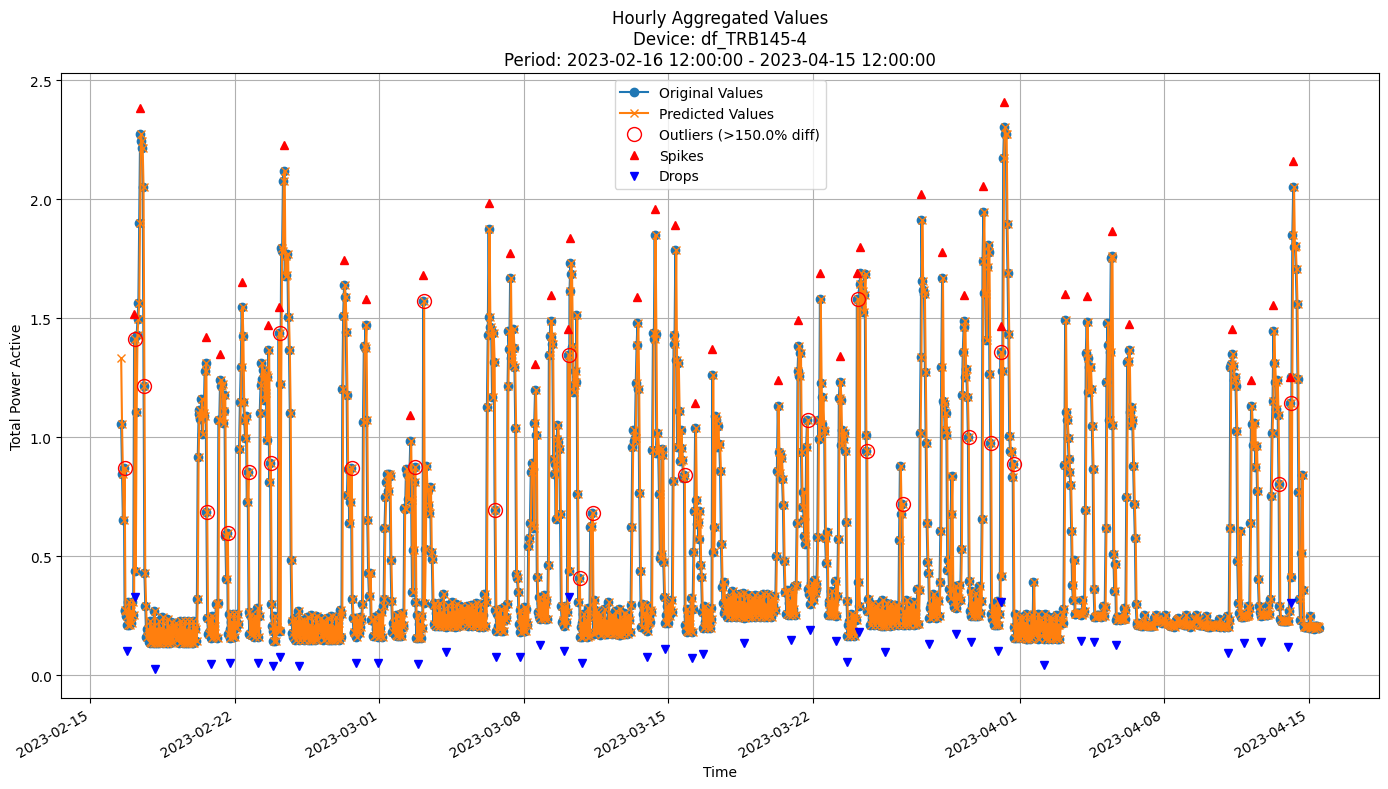


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2342
MAE: 0.1312
MAPE: 29.4605%

Directional Metrics:
Directional Accuracy: 37.3563%
First-Diff Correlation: -0.0258

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000
Drops:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000


In [10]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in baseline_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, baseline_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, baseline_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5,
                            )

### GBDT

In [11]:
update_freq = "14D"  # Update the model every 14 days
gbdt = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.03,
    subsample=0.8,
    max_depth=10,
    random_state=42)

In [12]:
gbdt_train_period_predictions, gbdt_valid_period_predictions, \
gbdt_train_period_metrics, gbdt_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model=gbdt, 
    train=train, 
    valid=valid, 
    incremental=False,
    data_freq=DATA_FREQUENCY, 
    update_freq=update_freq, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 12:00:00 to 2022-10-22 12:00:00

Time: 1.13 seconds
Memory usage after retraining: 0.0000 MB
Got predictions on training set
Predicting for chunk from 2022-10-22 13:00:00 to 2022-11-05 13:00:00

-------------------------

Retraining model on data from 2022-09-20 12:00:00 to 2022-11-05 13:00:00

Time: 1.73 seconds
Memory usage after retraining: 0.0000 MB
Predicting for chunk from 2022-11-05 14:00:00 to 2022-11-15 09:00:00

-------------------------
Metrics for Device: df_TRB145-4 | Period: 2022-10-22 13:00:00 - 2022-11-15 09:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3162
	MAE: 0.2192
	MAPE: 28.0543%

Directional Metrics:
	Directional Accuracy: 57.5175%
	First-Diff Correlation: 0.2840

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000


Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 12:00:00 to 2022-11-15 09:00:00

Time: 2.23 seconds
Memory usage after retraining: 0.0000 MB
Got predictions on training set
Predicting for chunk from 2022-11-15 10:00:00 to 2022-11-29 10:00:00

-------------------------

Retraining model on data from 2022-09-20 12:00:00 to 2022-11-29 10:00:00

Time: 2.96 seconds
Memory usage after retraining: 0.0000 MB
Predicting for chunk from 2022-11-29 11:00:00 to 2022-12-09 07:00:00

-------------------------
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 10:00:00 - 2022-12-09 07:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3023
	MAE: 0.1920
	MAPE: 34.8896%

Directional Metrics:
	Directional Accuracy: 54.9738%
	First-Diff Correlation: 0.3480

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000


Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 12:00:00 to 2023-03-12 08:00:00

Time: 7.40 seconds
Memory usage after retraining: 0.0000 MB
Got predictions on training set
Predicting for chunk from 2023-03-12 09:00:00 to 2023-03-26 09:00:00

-------------------------

Retraining model on data from 2022-09-20 12:00:00 to 2023-03-26 09:00:00

Time: 8.26 seconds
Memory usage after retraining: 0.0000 MB
Predicting for chunk from 2023-03-26 10:00:00 to 2023-04-05 06:00:00

-------------------------
Metrics for Device: df_TRB145-4 | Period: 2023-03-12 09:00:00 - 2023-04-05 06:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2176
	MAE: 0.1410
	MAPE: 30.0292%

Directional Metrics:
	Directional Accuracy: 52.7051%
	First-Diff Correlation: 0.3275

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.1176
		Recall: 0.1176
		F1: 0.1176


Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 12:00:00 to 2023-04-05 06:00:00

Time: 9.24 seconds
Memory usage after retraining: 0.0000 MB
Got predictions on training set
Predicting for chunk from 2023-04-05 07:00:00 to 2023-04-15 12:00:00

-------------------------
Metrics for Device: df_TRB145-4 | Period: 2023-04-05 07:00:00 - 2023-04-15 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1855
	MAE: 0.1059
	MAPE: 27.9060%

Directional Metrics:
	Directional Accuracy: 57.5510%
	First-Diff Correlation: 0.3597

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1429
		Recall: 0.1111
		F1: 0.1250
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.5714
		Recall: 0.4444
		F1: 0.5000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
---------------------------------------

#### Results

In [13]:
print("\n\nTrain period metrics:")
gbdt_all_time_train_metrics = all_time_aggregation_metrics(gbdt_train_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
gbdt_all_time_valid_metrics = all_time_aggregation_metrics(gbdt_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)
# Hourly Metrics:
# 	RMSE: 0.2486 ± 0.0612
# 	MAE: 0.1594 ± 0.0516
# 	MAPE: 33.4958% ± 5.3587%

# 	Directional Metrics:
# 		Directional Accuracy: 62.4754% ± 7.1041%
# 		First-Diff Correlation: 0.3821 ± 0.0970

# 	Immediate Detection (delta=0):
# 		Spike Precision: 0.1544 ± 0.1193
# 		Spike Recall: 0.1617 ± 0.1297
# 		Spike F1: 0.1577 ± 0.1238
# 		Drop Precision: 0.1459 ± 0.0857
# 		Drop Recall: 0.1534 ± 0.0909
# 		Drop F1: 0.1493 ± 0.0879

# 	1-Hour Delayed Detection (delta=1):
# 		Spike Precision: 0.4691 ± 0.2714
# 		Spike Recall: 0.4908 ± 0.2907
# 		Spike F1: 0.4788 ± 0.2795
# 		Drop Precision: 0.2117 ± 0.1062
# 		Drop Recall: 0.2201 ± 0.1161
# 		Drop F1: 0.2153 ± 0.1100



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.0453 ± 0.0065
	MAE: 0.0349 ± 0.0047
	MAPE: 8.0707% ± 1.5358%

	Directional Metrics:
		Directional Accuracy: 89.8489% ± 2.2812%
		First-Diff Correlation: 0.9869 ± 0.0056

	Immediate Detection (delta=0):
		Spike Precision: 0.4161 ± 0.3668
		Spike Recall: 0.5032 ± 0.4390
		Spike F1: 0.4539 ± 0.3965
		Drop Precision: 0.1185 ± 0.1091
		Drop Recall: 0.1433 ± 0.1262
		Drop F1: 0.1292 ± 0.1159

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.4574 ± 0.4057
		Spike Recall: 0.5508 ± 0.4780
		Spike F1: 0.4980 ± 0.4353
		Drop Precision: 0.1185 ± 0.1091
		Drop Recall: 0.1433 ± 0.1262
		Drop F1: 0.1292 ± 0.1159
Daily Metrics:
	RMSE: 0.4098 ± 0.0416
	MAE: 0.3117 ± 0.0414
	MAPE: 2.9693% ± 0.3961%

	Directional Metrics:
		Directional Accuracy: 96.1398% ± 1.8835%
		First-Diff Correlation: 0.9996 ± 0.0001

	Immediate Detection (delta=0):
	

#### Feature importance
[WiP] Right now only for the last split and last device

In [14]:
feat_imps = sorted(
    zip(features[2:], gbdt.feature_importances_), key=lambda x: x[1], reverse=True
)
feat_imps


[('L1_current_lag_1h', 0.5021169750047882),
 ('L2_act_power_lag_1h', 0.099630777084705),
 ('hour', 0.07972246725830173),
 ('L2_current_lag_1h', 0.05195129216885085),
 ('L1_app_power_lag_1h', 0.0462906126823782),
 ('L3_react_power_lag_1h', 0.03217175879615877),
 ('month', 0.015107346679072608),
 ('L2_app_power_lag_1h', 0.013036022872189901),
 ('grid_freq_lag_1h', 0.009844420017667525),
 ('powerfactor3_lag_1h', 0.008160666279480488),
 ('L3_react_power_lag_24h', 0.00790285290902993),
 ('grid_freq_lag_24h', 0.007117470072761487),
 ('L3_act_power_lag_1h', 0.007105469064166979),
 ('powerfactor2_lag_24h', 0.006356506652744368),
 ('L2_act_power_lag_24h', 0.006083319804709732),
 ('weekday', 0.005738168746954138),
 ('L1_react_power_lag_24h', 0.005737438832858653),
 ('powerfactor1_lag_1h', 0.005408990567748326),
 ('powerfactor1_lag_24h', 0.005405235366324371),
 ('L2_react_power_lag_24h', 0.004900994545040569),
 ('L1_act_power_lag_1h', 0.00489792982073481),
 ('L1_react_power_lag_1h', 0.00481490275

#### Training plots

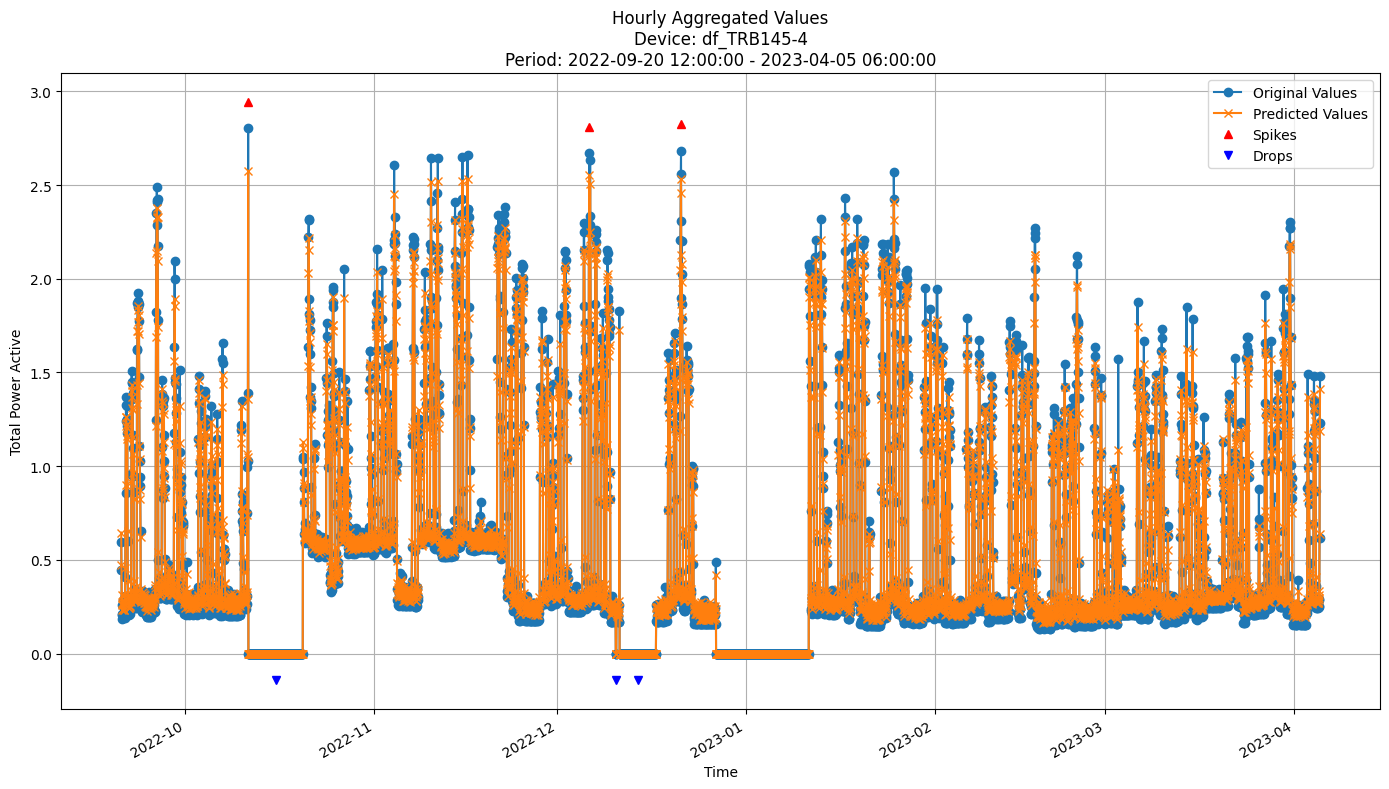


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.0553
MAE: 0.0413
MAPE: 10.3034%

Directional Metrics:
Directional Accuracy: 85.6785%
First-Diff Correlation: 0.9762

Immediate Detection (delta=0):
Spikes:
  Precision: 0.6379
  Recall: 0.8222
  F1 Score: 0.7184
Drops:
  Precision: 0.1754
  Recall: 0.2273
  F1 Score: 0.1980

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7414
  Recall: 0.9556
  F1 Score: 0.8350
Drops:
  Precision: 0.1754
  Recall: 0.2273
  F1 Score: 0.1980


In [15]:
for device_id in gbdt_train_period_predictions.keys():
    y_train = gbdt_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = gbdt_train_period_predictions[device_id][-1]['y_pred']
    
    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)
# 0.17, 0.12, 25.55, 70.81%, 0.72

#### Validation plots
Plot only the last few periods of predictions

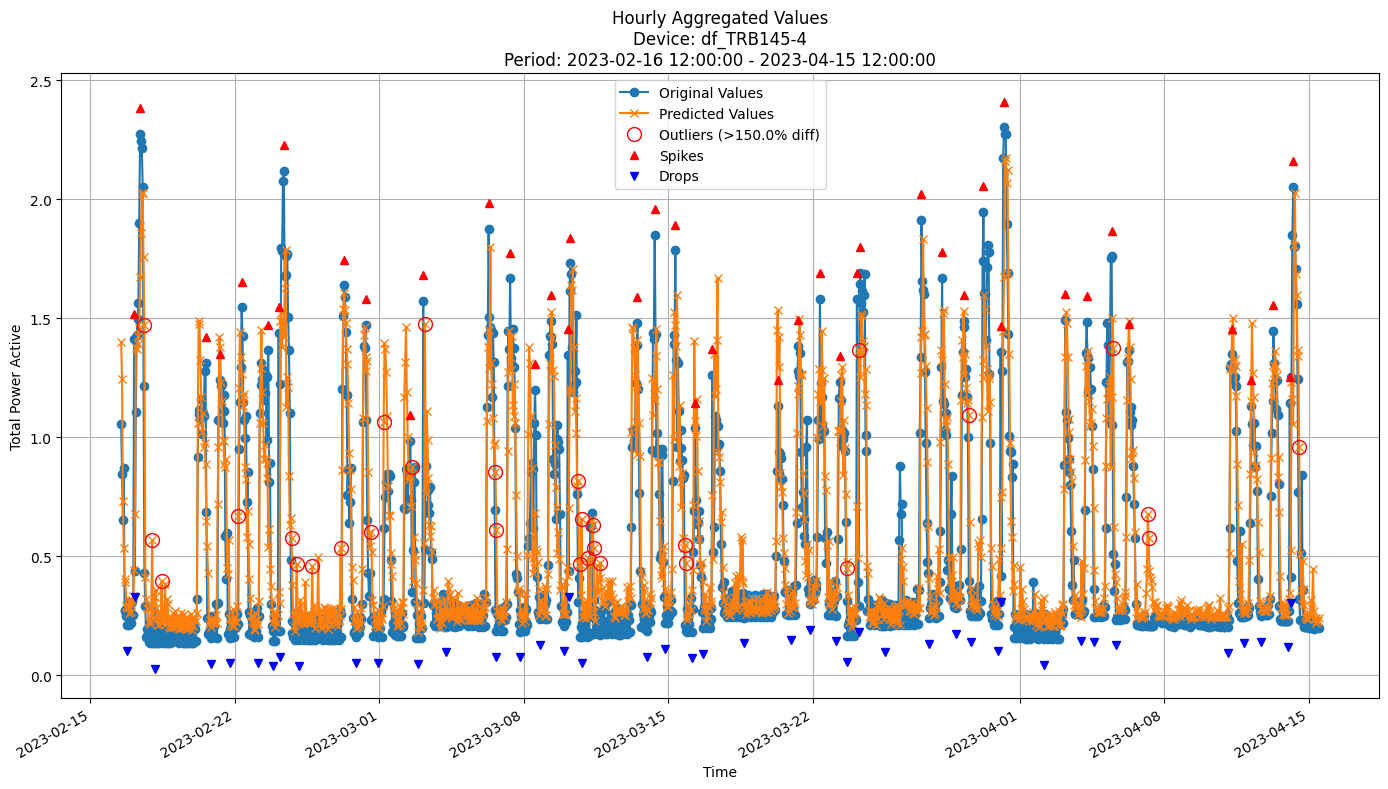


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2185
MAE: 0.1378
MAPE: 33.1683%

Directional Metrics:
Directional Accuracy: 58.4770%
First-Diff Correlation: 0.3531

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0769
  Recall: 0.0682
  F1 Score: 0.0723
Drops:
  Precision: 0.1538
  Recall: 0.1364
  F1 Score: 0.1446

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.4103
  Recall: 0.3636
  F1 Score: 0.3855
Drops:
  Precision: 0.2051
  Recall: 0.1818
  F1 Score: 0.1928


In [16]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in gbdt_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, gbdt_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, gbdt_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

# 0.22, 0.15, 39.79, 60.39%, 0.39

### Random Forest model

In [17]:
update_freq = "14D"  # Update the model every 14 days
rf = RandomForestRegressor(
    n_estimators=100, 
    max_depth=10,
    max_features='sqrt',
    random_state=42, 
    n_jobs=-1)


In [18]:
rf_train_period_predictions, rf_valid_period_predictions, \
rf_train_period_metrics, rf_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model=rf, 
    train=train, 
    valid=valid, 
    incremental=False,
    data_freq=DATA_FREQUENCY, 
    update_freq=update_freq, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 12:00:00 to 2022-10-22 12:00:00

Time: 0.12 seconds
Memory usage after retraining: 0.0000 MB
Got predictions on training set
Predicting for chunk from 2022-10-22 13:00:00 to 2022-11-05 13:00:00

-------------------------

Retraining model on data from 2022-09-20 12:00:00 to 2022-11-05 13:00:00

Time: 0.12 seconds
Memory usage after retraining: 0.0000 MB
Predicting for chunk from 2022-11-05 14:00:00 to 2022-11-15 09:00:00

-------------------------
Metrics for Device: df_TRB145-4 | Period: 2022-10-22 13:00:00 - 2022-11-15 09:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2787
	MAE: 0.1784
	MAPE: 21.2983%

Directional Metrics:
	Directional Accuracy: 59.9650%
	First-Diff Correlation: 0.3538

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000


Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 12:00:00 to 2022-11-15 09:00:00

Time: 0.13 seconds
Memory usage after retraining: 0.0000 MB
Got predictions on training set
Predicting for chunk from 2022-11-15 10:00:00 to 2022-11-29 10:00:00

-------------------------

Retraining model on data from 2022-09-20 12:00:00 to 2022-11-29 10:00:00

Time: 0.13 seconds
Memory usage after retraining: 0.0000 MB
Predicting for chunk from 2022-11-29 11:00:00 to 2022-12-09 07:00:00

-------------------------
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 10:00:00 - 2022-12-09 07:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3011
	MAE: 0.1913
	MAPE: 30.1723%

Directional Metrics:
	Directional Accuracy: 52.7051%
	First-Diff Correlation: 0.4123

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000


Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 12:00:00 to 2023-03-12 08:00:00

Time: 0.20 seconds
Memory usage after retraining: 0.0000 MB
Got predictions on training set
Predicting for chunk from 2023-03-12 09:00:00 to 2023-03-26 09:00:00

-------------------------

Retraining model on data from 2022-09-20 12:00:00 to 2023-03-26 09:00:00

Time: 0.19 seconds
Memory usage after retraining: 0.0000 MB
Predicting for chunk from 2023-03-26 10:00:00 to 2023-04-05 06:00:00

-------------------------
Metrics for Device: df_TRB145-4 | Period: 2023-03-12 09:00:00 - 2023-04-05 06:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2296
	MAE: 0.1482
	MAPE: 31.6333%

Directional Metrics:
	Directional Accuracy: 52.8796%
	First-Diff Correlation: 0.2864

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0588
		Recall: 0.0588
		F1: 0.0588
	Drops:
		Precision: 0.0588
		Recall: 0.0588
		F1: 0.0588


Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 12:00:00 to 2023-04-05 06:00:00

Time: 0.22 seconds
Memory usage after retraining: 0.0000 MB
Got predictions on training set
Predicting for chunk from 2023-04-05 07:00:00 to 2023-04-15 12:00:00

-------------------------
Metrics for Device: df_TRB145-4 | Period: 2023-04-05 07:00:00 - 2023-04-15 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1792
	MAE: 0.0985
	MAPE: 24.4696%

Directional Metrics:
	Directional Accuracy: 60.0000%
	First-Diff Correlation: 0.4165

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.5000
		Recall: 0.3333
		F1: 0.4000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.6667
		Recall: 0.4444
		F1: 0.5333
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
---------------------------------------

#### Results

In [19]:
print("\n\nTrain period metrics:")
rf_all_time_train_metrics = all_time_aggregation_metrics(rf_train_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
rf_all_time_valid_metrics = all_time_aggregation_metrics(rf_train_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)

# Best values:
# Hourly Metrics:
# 	RMSE: 0.2221 ± 0.0148
# 	MAE: 0.1267 ± 0.0092
# 	MAPE: 22.1472% ± 2.0063%

# 	Directional Metrics:
# 		Directional Accuracy: 60.8511% ± 2.9815%
# 		First-Diff Correlation: 0.4859 ± 0.0565

# 	Immediate Detection (delta=0):
# 		Spike Precision: 0.2094 ± 0.0638
# 		Spike Recall: 0.1844 ± 0.0780
# 		Spike F1: 0.1927 ± 0.0741
# 		Drop Precision: 0.0547 ± 0.0125
# 		Drop Recall: 0.1408 ± 0.0536
# 		Drop F1: 0.0779 ± 0.0216

# 	1-Hour Delayed Detection (delta=1):
# 		Spike Precision: 0.4647 ± 0.0473
# 		Spike Recall: 0.3984 ± 0.1023
# 		Spike F1: 0.4191 ± 0.0799
# 		Drop Precision: 0.1104 ± 0.0172
# 		Drop Recall: 0.2821 ± 0.0884
# 		Drop F1: 0.1571 ± 0.0324



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.1152 ± 0.0115
	MAE: 0.0710 ± 0.0066
	MAPE: 13.0962% ± 1.7947%

	Directional Metrics:
		Directional Accuracy: 78.9328% ± 2.4785%
		First-Diff Correlation: 0.8833 ± 0.0258

	Immediate Detection (delta=0):
		Spike Precision: 0.1899 ± 0.2229
		Spike Recall: 0.1333 ± 0.1746
		Spike F1: 0.1508 ± 0.1884
		Drop Precision: 0.0927 ± 0.1070
		Drop Recall: 0.0632 ± 0.0828
		Drop F1: 0.0716 ± 0.0880

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.2955 ± 0.3437
		Spike Recall: 0.2127 ± 0.2853
		Spike F1: 0.2380 ± 0.3004
		Drop Precision: 0.0970 ± 0.1123
		Drop Recall: 0.0664 ± 0.0869
		Drop F1: 0.0753 ± 0.0929
Daily Metrics:
	RMSE: 0.7521 ± 0.0838
	MAE: 0.5206 ± 0.0680
	MAPE: 3.8482% ± 0.4569%

	Directional Metrics:
		Directional Accuracy: 92.8894% ± 1.2605%
		First-Diff Correlation: 0.9956 ± 0.0014

	Immediate Detection (delta=0):


#### Feature importance
[WiP] Right now only for the last split and last device

In [20]:
feat_imps = sorted(
    zip(features[2:], rf.feature_importances_), key=lambda x: x[1], reverse=True
)
feat_imps


[('L1_current_lag_1h', 0.1271317426497017),
 ('L2_current_lag_1h', 0.09709935220053245),
 ('L3_act_power_lag_1h', 0.07108573514591392),
 ('L1_act_power_lag_1h', 0.0708785784997985),
 ('L2_act_power_lag_1h', 0.06315521563610535),
 ('L1_app_power_lag_1h', 0.06309946611672196),
 ('powerfactor3_lag_1h', 0.062201250982591307),
 ('L2_app_power_lag_1h', 0.05483795496074711),
 ('L3_app_power_lag_1h', 0.0464553533545638),
 ('hour', 0.04146166577575691),
 ('L3_current_lag_1h', 0.04015568606672648),
 ('L2_current_lag_24h', 0.021052282462170648),
 ('L2_react_power_lag_1h', 0.01988740813196654),
 ('L1_react_power_lag_1h', 0.019569078607514303),
 ('L1_app_power_lag_24h', 0.016477962039101245),
 ('L2_act_power_lag_24h', 0.015913369776274066),
 ('L2_app_power_lag_24h', 0.015001505818020821),
 ('L1_current_lag_24h', 0.012859027094478582),
 ('L3_react_power_lag_1h', 0.012214912350232383),
 ('L1_act_power_lag_24h', 0.009260164889030191),
 ('powerfactor3_lag_24h', 0.008534480448626102),
 ('L1_react_power_

#### Training plots
Plot only the last period of predictions

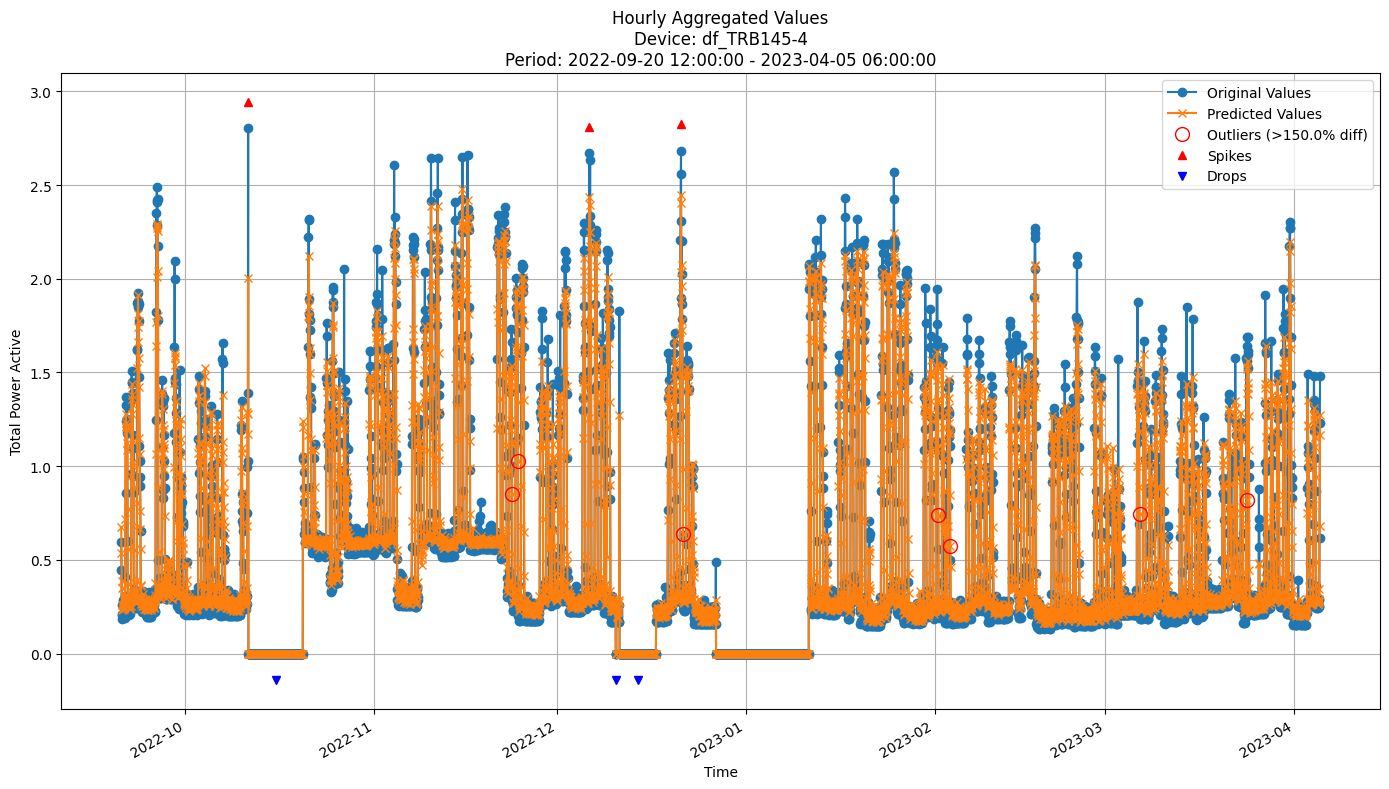


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1317
MAE: 0.0806
MAPE: 15.9035%

Directional Metrics:
Directional Accuracy: 74.7121%
First-Diff Correlation: 0.8383

Immediate Detection (delta=0):
Spikes:
  Precision: 0.5294
  Recall: 0.4000
  F1 Score: 0.4557
Drops:
  Precision: 0.2121
  Recall: 0.1591
  F1 Score: 0.1818

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7353
  Recall: 0.5556
  F1 Score: 0.6329
Drops:
  Precision: 0.2424
  Recall: 0.1818
  F1 Score: 0.2078


In [21]:
for device_id in rf_train_period_predictions.keys():
    y_train = rf_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = rf_train_period_predictions[device_id][-1]['y_pred']
    plot_hourly_predictions(y_train, 
                            y_pred_train,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last periods of predictions

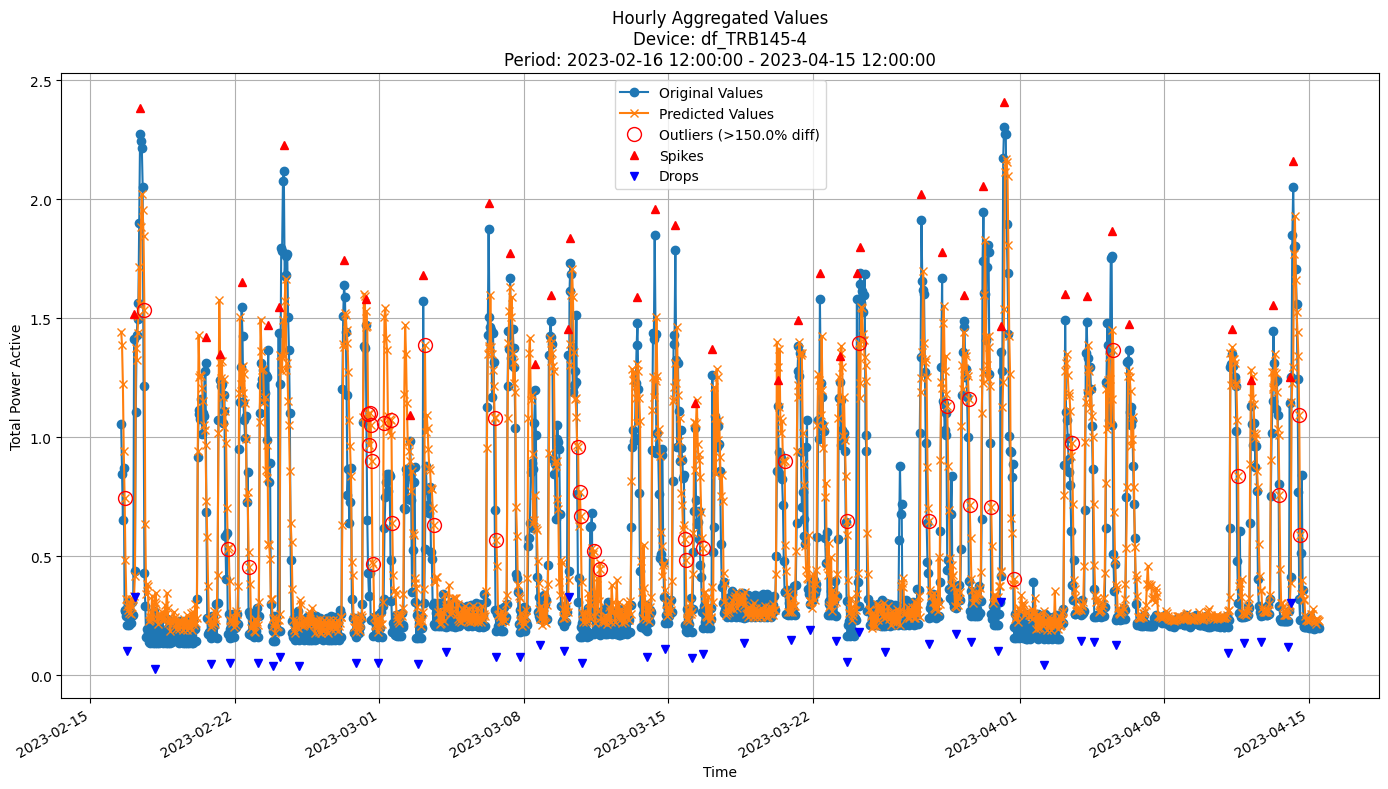


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2313
MAE: 0.1416
MAPE: 33.3903%

Directional Metrics:
Directional Accuracy: 58.3333%
First-Diff Correlation: 0.3691

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1282
  Recall: 0.1136
  F1 Score: 0.1205
Drops:
  Precision: 0.1282
  Recall: 0.1136
  F1 Score: 0.1205

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.3333
  Recall: 0.2955
  F1 Score: 0.3133
Drops:
  Precision: 0.1538
  Recall: 0.1364
  F1 Score: 0.1446


In [22]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in rf_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, rf_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, rf_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### Hoeffding Tree

In [23]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

grace_period = 10
delta = 0.5
max_depth = 10
tau = 0.05

hoef = HoeffdingTreeRegressor(
        max_depth=max_depth,
        grace_period=grace_period,
        delta=delta,
        tau=tau,
        leaf_prediction="mean"
    )


In [24]:
hoef_all_train_preds, hoef_all_valid_preds, \
hoef_all_train_metrics, hoef_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model=hoef, 
    train=train, 
    valid=valid, 
    incremental=True,
    data_freq=DATA_FREQUENCY,
    update_freq=update_freq, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-10-22 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-10-22 13:00:00 - 2022-11-15 09:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3978
	MAE: 0.2563
	MAPE: 27.4439%

Directional Metrics:
	Directional Accuracy: 47.5524%
	First-Diff Correlation: 0.1595

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 5.0512
	MAE: 3.8

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-11-15 09:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 10:00:00 - 2022-12-09 07:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.4032
	MAE: 0.2650
	MAPE: 39.9377%

Directional Metrics:
	Directional Accuracy: 50.2618%
	First-Diff Correlation: 0.2158

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 4.3860
	MAE: 3.2

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-03-12 08:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-03-12 09:00:00 - 2023-04-05 06:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3195
	MAE: 0.2023
	MAPE: 42.2304%

Directional Metrics:
	Directional Accuracy: 42.9319%
	First-Diff Correlation: 0.1999

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.2500
		Recall: 0.0588
		F1: 0.0952
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 3.2725
	MAE: 2.3

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-04-05 06:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-04-05 07:00:00 - 2023-04-15 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2840
	MAE: 0.1644
	MAPE: 42.0583%

Directional Metrics:
	Directional Accuracy: 50.2041%
	First-Diff Correlation: 0.2272

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.1429
		Recall: 0.1111
		F1: 0.1250
	Drops:
		Precision: 0.1667
		Recall: 0.1111
		F1: 0.1333
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 2.6981
	MAE: 1.9

#### Results

In [25]:
print("\n\nTrain period metrics:")
hoef_all_time_train_metrics = all_time_aggregation_metrics(hoef_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
hoef_all_time_valid_metrics = all_time_aggregation_metrics(hoef_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.3150 ± 0.0867
	MAE: 0.2003 ± 0.0659
	MAPE: 36.8348% ± 14.9310%

	Directional Metrics:
		Directional Accuracy: 39.7363% ± 7.9271%
		First-Diff Correlation: 0.3416 ± 0.1091

	Immediate Detection (delta=0):
		Spike Precision: 0.1056 ± 0.1246
		Spike Recall: 0.0730 ± 0.0887
		Spike F1: 0.0856 ± 0.1023
		Drop Precision: 0.0579 ± 0.0713
		Drop Recall: 0.0601 ± 0.0796
		Drop F1: 0.0583 ± 0.0746

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.2109 ± 0.2486
		Spike Recall: 0.1413 ± 0.1645
		Spike F1: 0.1677 ± 0.1950
		Drop Precision: 0.0716 ± 0.0834
		Drop Recall: 0.0715 ± 0.0868
		Drop F1: 0.0706 ± 0.0833
Daily Metrics:
	RMSE: 3.0778 ± 1.4050
	MAE: 2.2249 ± 1.0467
	MAPE: 17.5757% ± 10.0102%

	Directional Metrics:
		Directional Accuracy: 80.5341% ± 3.2742%
		First-Diff Correlation: 0.8956 ± 0.0900

	Immediate Detection (delta=0

#### Training plots
Plot only the last period of predictions

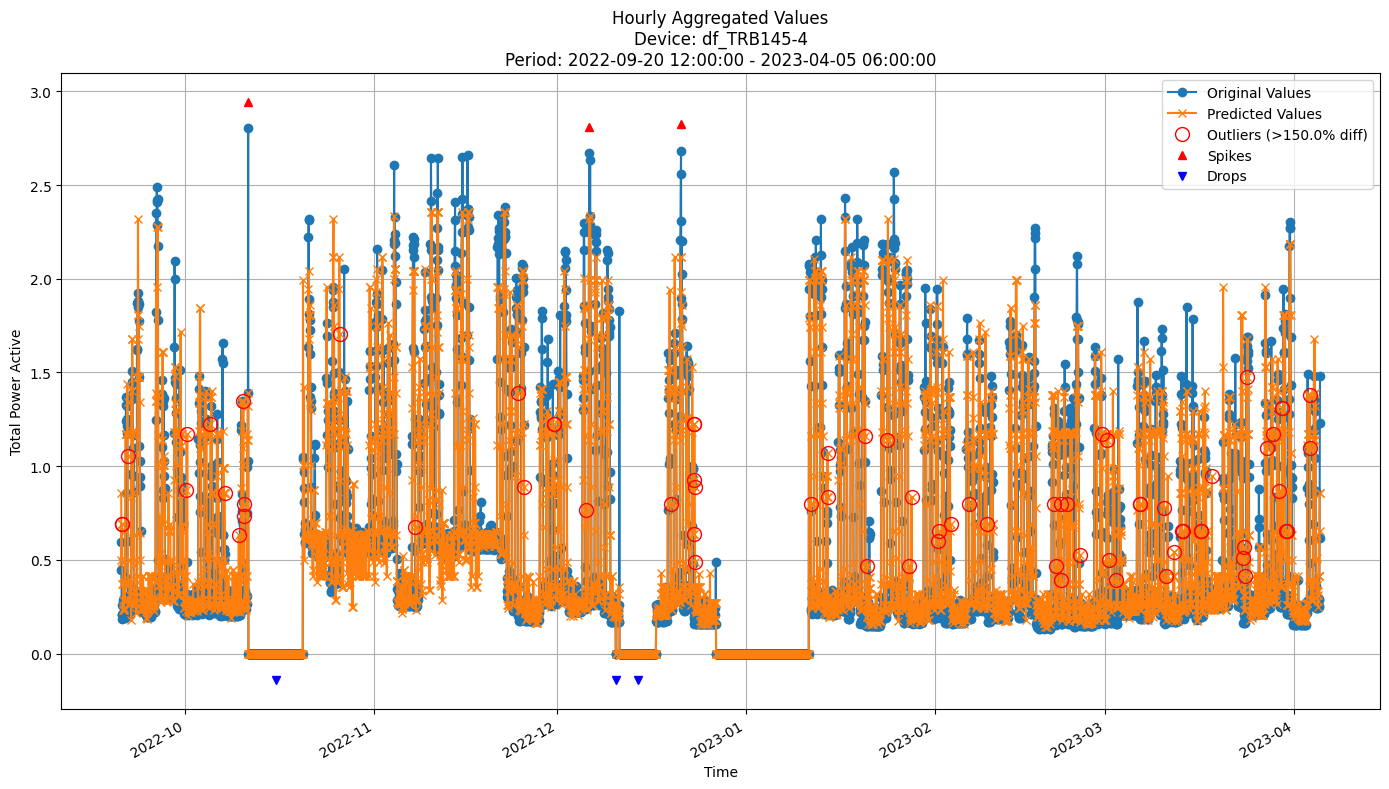


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2445
MAE: 0.1480
MAPE: 28.0910%

Directional Metrics:
Directional Accuracy: 47.6965%
First-Diff Correlation: 0.4413

Immediate Detection (delta=0):
Spikes:
  Precision: 0.2083
  Recall: 0.1111
  F1 Score: 0.1449
Drops:
  Precision: 0.1000
  Recall: 0.0682
  F1 Score: 0.0811

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.5417
  Recall: 0.2889
  F1 Score: 0.3768
Drops:
  Precision: 0.1667
  Recall: 0.1136
  F1 Score: 0.1351


In [26]:
for device_id in hoef_all_train_preds.keys():
    y_train = hoef_all_train_preds[device_id][-1]['y_true']
    y_pred_train = hoef_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

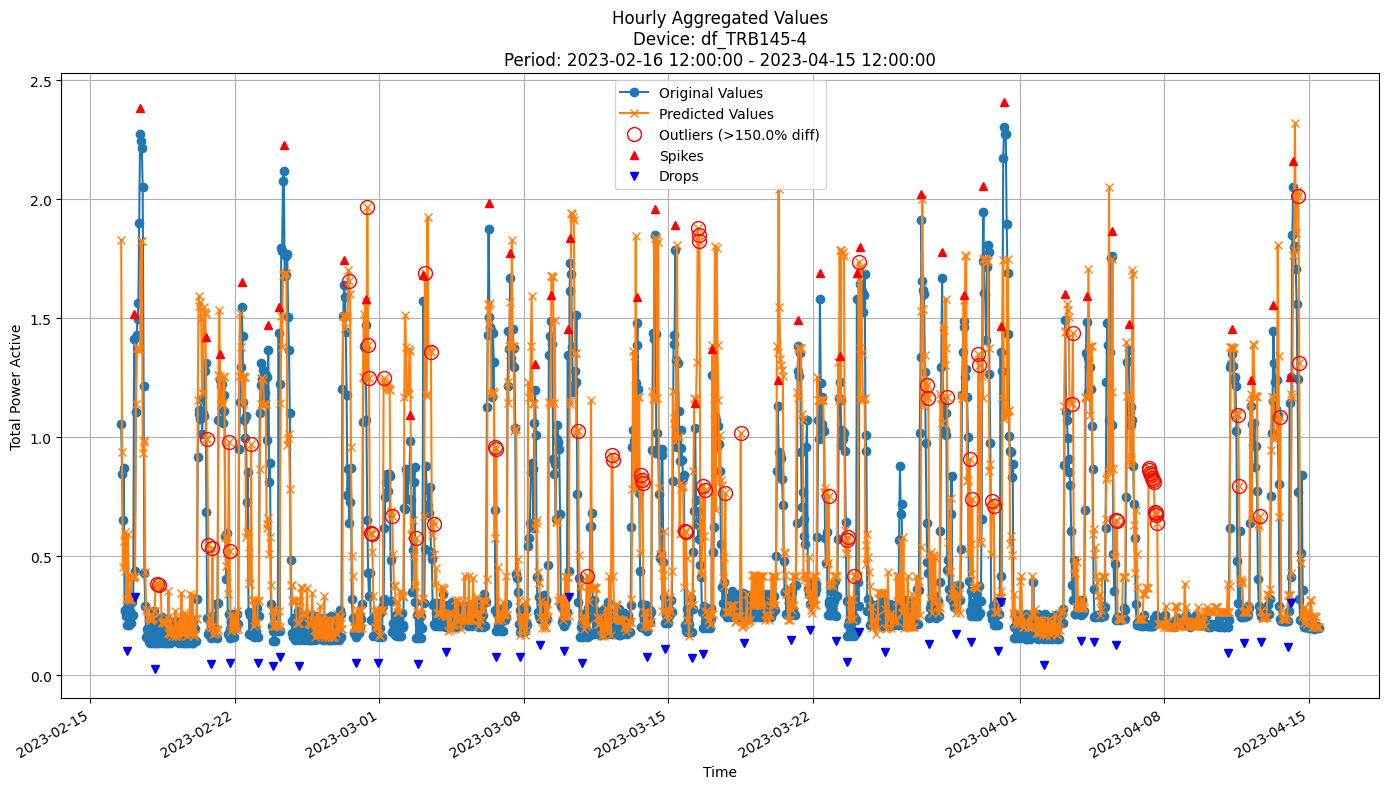


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.3044
MAE: 0.1877
MAPE: 43.1167%

Directional Metrics:
Directional Accuracy: 50.2155%
First-Diff Correlation: 0.2607

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0323
  Recall: 0.0227
  F1 Score: 0.0267
Drops:
  Precision: 0.0968
  Recall: 0.0682
  F1 Score: 0.0800

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.2903
  Recall: 0.2045
  F1 Score: 0.2400
Drops:
  Precision: 0.2258
  Recall: 0.1591
  F1 Score: 0.1867


In [27]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in hoef_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, hoef_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, hoef_all_valid_preds[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### ARF (Hoeffding Tree)

In [28]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

n_models = 10
max_features = 0.8
grace_period = 10
split_confidence = 0.5
depth = 10
tau = 0.01

arf_hf = ARFRegressor(
        n_models=n_models,
        max_features=max_features,
        aggregation_method='median',
        grace_period=grace_period,
        max_depth=depth,
        delta=split_confidence,
        tau=tau,
        seed=42,
    )

In [29]:
arf_hf_all_train_preds, arf_hf_all_valid_preds, \
arf_hf_all_train_metrics, arf_hf_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model=arf_hf,
    train=train,
    valid=valid,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    update_freq=update_freq,
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-10-22 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-10-22 13:00:00 - 2022-11-15 09:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3405
	MAE: 0.2352
	MAPE: 31.8058%

Directional Metrics:
	Directional Accuracy: 49.8252%
	First-Diff Correlation: 0.2879

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 4.4627
	MAE: 3.5

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-11-15 09:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 10:00:00 - 2022-12-09 07:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3442
	MAE: 0.2426
	MAPE: 45.5051%

Directional Metrics:
	Directional Accuracy: 56.5445%
	First-Diff Correlation: 0.3846

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 3.9387
	MAE: 3.1

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-03-12 08:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-03-12 09:00:00 - 2023-04-05 06:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2483
	MAE: 0.1708
	MAPE: 39.8397%

Directional Metrics:
	Directional Accuracy: 51.8325%
	First-Diff Correlation: 0.3053

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1429
		Recall: 0.0588
		F1: 0.0833
	Drops:
		Precision: 0.1667
		Recall: 0.0588
		F1: 0.0870

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.4286
		Recall: 0.1765
		F1: 0.2500
	Drops:
		Precision: 0.1667
		Recall: 0.0588
		F1: 0.0870
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 2.6744
	MAE: 2.2

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-04-05 06:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-04-05 07:00:00 - 2023-04-15 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2191
	MAE: 0.1486
	MAPE: 43.0197%

Directional Metrics:
	Directional Accuracy: 55.9184%
	First-Diff Correlation: 0.4527

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.2000
		Recall: 0.1111
		F1: 0.1429
	Drops:
		Precision: 0.2000
		Recall: 0.1111
		F1: 0.1429
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 2.6913
	MAE: 2.3

#### Results

In [30]:
print("\n\nTrain period metrics:")
arf_hf_all_time_train_metrics = all_time_aggregation_metrics(arf_hf_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
arf_hf_all_time_valid_metrics = all_time_aggregation_metrics(arf_hf_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.2768 ± 0.0723
	MAE: 0.1890 ± 0.0713
	MAPE: 40.8739% ± 22.0890%

	Directional Metrics:
		Directional Accuracy: 55.9934% ± 9.1942%
		First-Diff Correlation: 0.4715 ± 0.1300

	Immediate Detection (delta=0):
		Spike Precision: 0.0857 ± 0.1216
		Spike Recall: 0.0444 ± 0.0617
		Spike F1: 0.0539 ± 0.0756
		Drop Precision: 0.0212 ± 0.0401
		Drop Recall: 0.0339 ± 0.0741
		Drop F1: 0.0253 ± 0.0518

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.1619 ± 0.2299
		Spike Recall: 0.0825 ± 0.1100
		Spike F1: 0.1001 ± 0.1354
		Drop Precision: 0.0535 ± 0.1063
		Drop Recall: 0.0881 ± 0.1979
		Drop F1: 0.0649 ± 0.1381
Daily Metrics:
	RMSE: 3.0736 ± 1.2041
	MAE: 2.3295 ± 0.9760
	MAPE: 21.0970% ± 12.2377%

	Directional Metrics:
		Directional Accuracy: 84.2771% ± 3.9899%
		First-Diff Correlation: 0.9140 ± 0.1058

	Immediate Detection (delta=0

#### Training plots

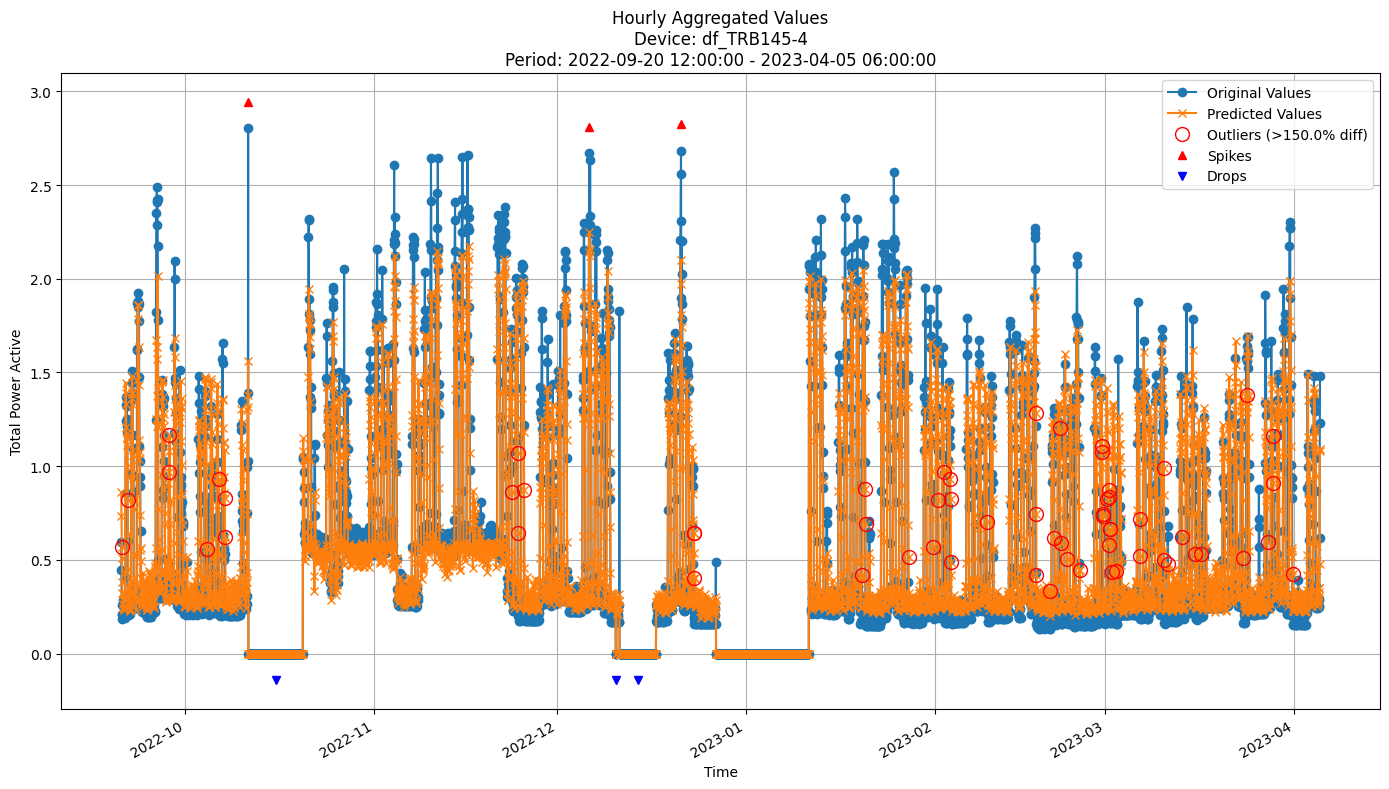


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2284
MAE: 0.1444
MAPE: 29.6842%

Directional Metrics:
Directional Accuracy: 60.9915%
First-Diff Correlation: 0.5456

Immediate Detection (delta=0):
Spikes:
  Precision: 0.2667
  Recall: 0.1778
  F1 Score: 0.2133
Drops:
  Precision: 0.0333
  Recall: 0.0227
  F1 Score: 0.0270

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.4667
  Recall: 0.3111
  F1 Score: 0.3733
Drops:
  Precision: 0.0667
  Recall: 0.0455
  F1 Score: 0.0541


In [31]:
for device_id in arf_hf_all_train_preds.keys():
    y_train = arf_hf_all_train_preds[device_id][-1]['y_true']
    y_pred_train = arf_hf_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

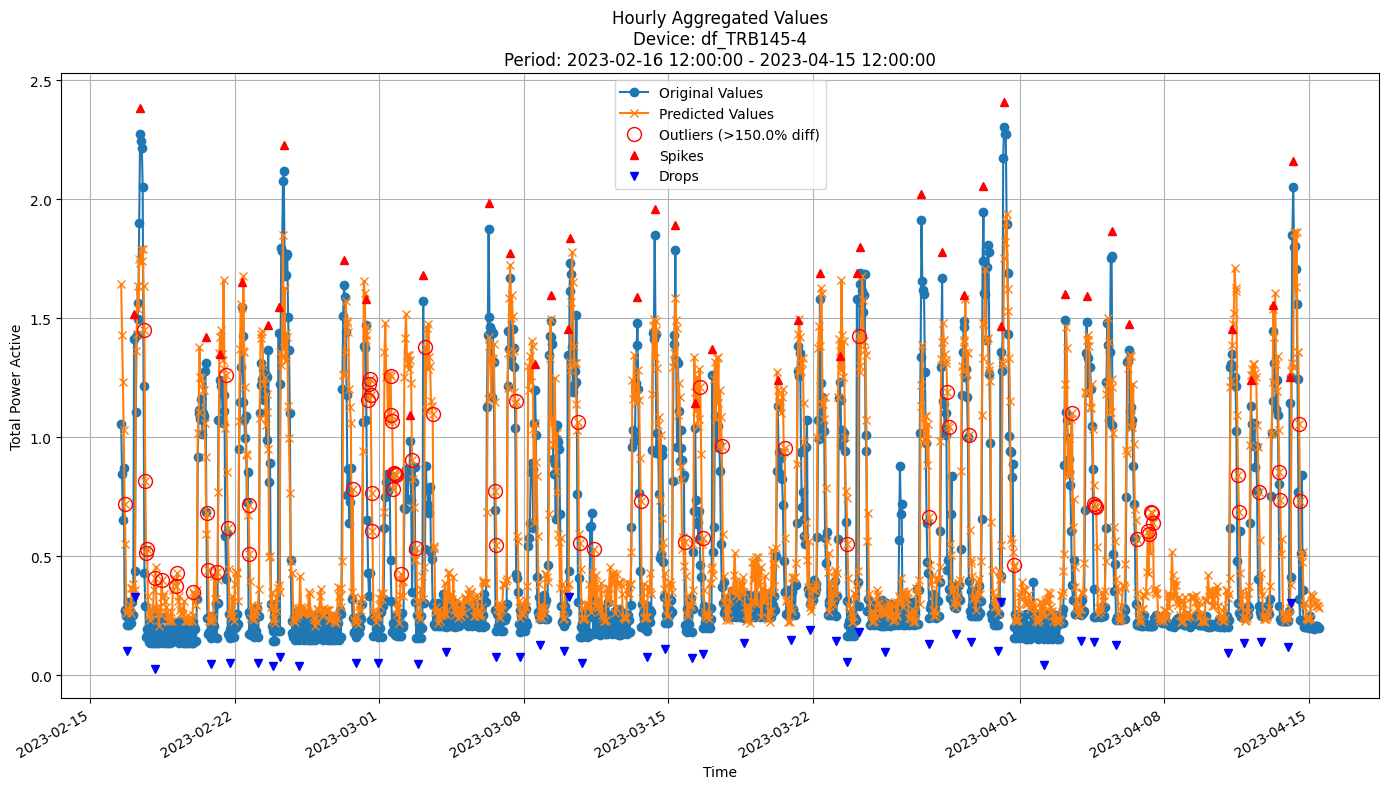


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2604
MAE: 0.1777
MAPE: 46.6985%

Directional Metrics:
Directional Accuracy: 55.6034%
First-Diff Correlation: 0.3625

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1290
  Recall: 0.0909
  F1 Score: 0.1067
Drops:
  Precision: 0.0645
  Recall: 0.0455
  F1 Score: 0.0533

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.4194
  Recall: 0.2955
  F1 Score: 0.3467
Drops:
  Precision: 0.2258
  Recall: 0.1591
  F1 Score: 0.1867


In [32]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in arf_hf_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, arf_hf_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, arf_hf_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

### FastODT

In [33]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario
grace_period = 10
split_confidence = 0.005
depth = 50
eagerness = 100
grace_period_depth = 0 # set to 1 to use only for first node, set to -1 to use for all nodes, set to N to use for N nodes
fodt = fastodt.FastODT(
        depth=depth,
        grace_period=grace_period,
        split_confidence=split_confidence,
        option='hf',
        eagerness = eagerness,
        grace_period_depth = -1
    )

In [34]:
fodt_all_train_preds, fodt_all_valid_preds, \
fodt_all_train_metrics, fodt_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model=fodt, 
    train=train, 
    valid=valid, 
    incremental=True, 
    data_freq=DATA_FREQUENCY,
    update_freq=update_freq, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-10-22 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-10-22 13:00:00 - 2022-11-15 09:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.5380
	MAE: 0.3823
	MAPE: 42.9158%

Directional Metrics:
	Directional Accuracy: 50.8741%
	First-Diff Correlation: 0.1252

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 9.0121
	MAE: 7.2

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-11-15 09:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 10:00:00 - 2022-12-09 07:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.5823
	MAE: 0.4325
	MAPE: 73.4042%

Directional Metrics:
	Directional Accuracy: 54.6248%
	First-Diff Correlation: 0.3135

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 8.6614
	MAE: 7.2

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-03-12 08:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-03-12 09:00:00 - 2023-04-05 06:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3383
	MAE: 0.2733
	MAPE: 83.9679%

Directional Metrics:
	Directional Accuracy: 57.0681%
	First-Diff Correlation: 0.4037

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 5.2377
	MAE: 4.3

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-04-05 06:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-04-05 07:00:00 - 2023-04-15 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.4075
	MAE: 0.3250
	MAPE: 127.4055%

Directional Metrics:
	Directional Accuracy: 54.6939%
	First-Diff Correlation: 0.4442

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 7.1649
	MAE: 5.

#### Results

In [35]:
print("\n\nTrain period metrics:")
fodt_all_time_train_metrics = all_time_aggregation_metrics(fodt_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
fodt_all_time_valid_metrics = all_time_aggregation_metrics(fodt_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.4594 ± 0.0242
	MAE: 0.3457 ± 0.0206
	MAPE: 76.2068% ± 8.8171%

	Directional Metrics:
		Directional Accuracy: 52.8257% ± 11.6423%
		First-Diff Correlation: 0.3724 ± 0.1064

	Immediate Detection (delta=0):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000
Daily Metrics:
	RMSE: 6.5481 ± 0.5628
	MAE: 4.8829 ± 0.6013
	MAPE: 46.3733% ± 5.0394%

	Directional Metrics:
		Directional Accuracy: 58.9755% ± 19.1824%
		First-Diff Correlation: 0.4934 ± 0.0814

	Immediate Detection (delta=0

#### Training plots


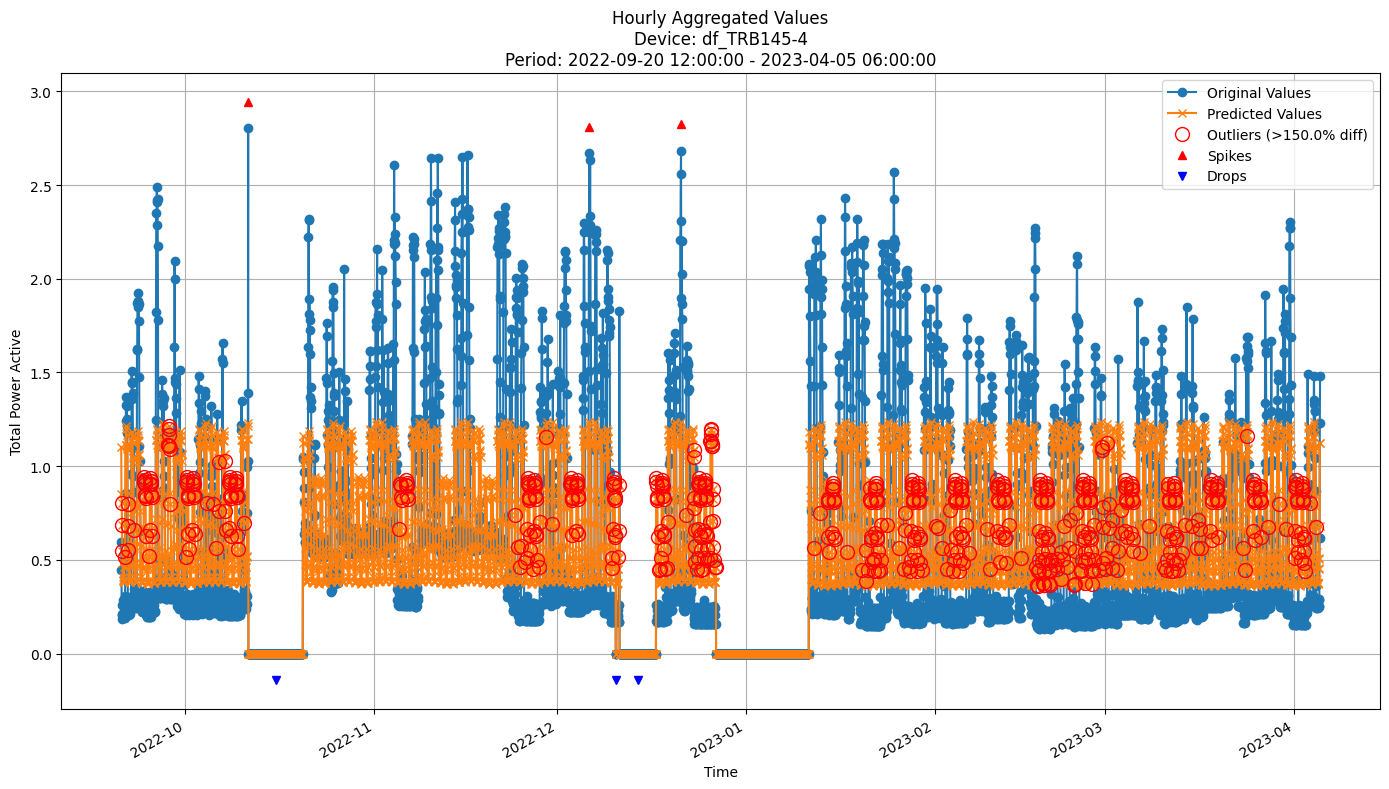


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.4235
MAE: 0.3281
MAPE: 84.4458%

Directional Metrics:
Directional Accuracy: 58.9885%
First-Diff Correlation: 0.4769

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [36]:
for device_id in fodt_all_train_preds.keys():
    y_train = fodt_all_train_preds[device_id][-1]['y_true']
    y_pred_train = fodt_all_train_preds[device_id][-1]['y_pred']
    
    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

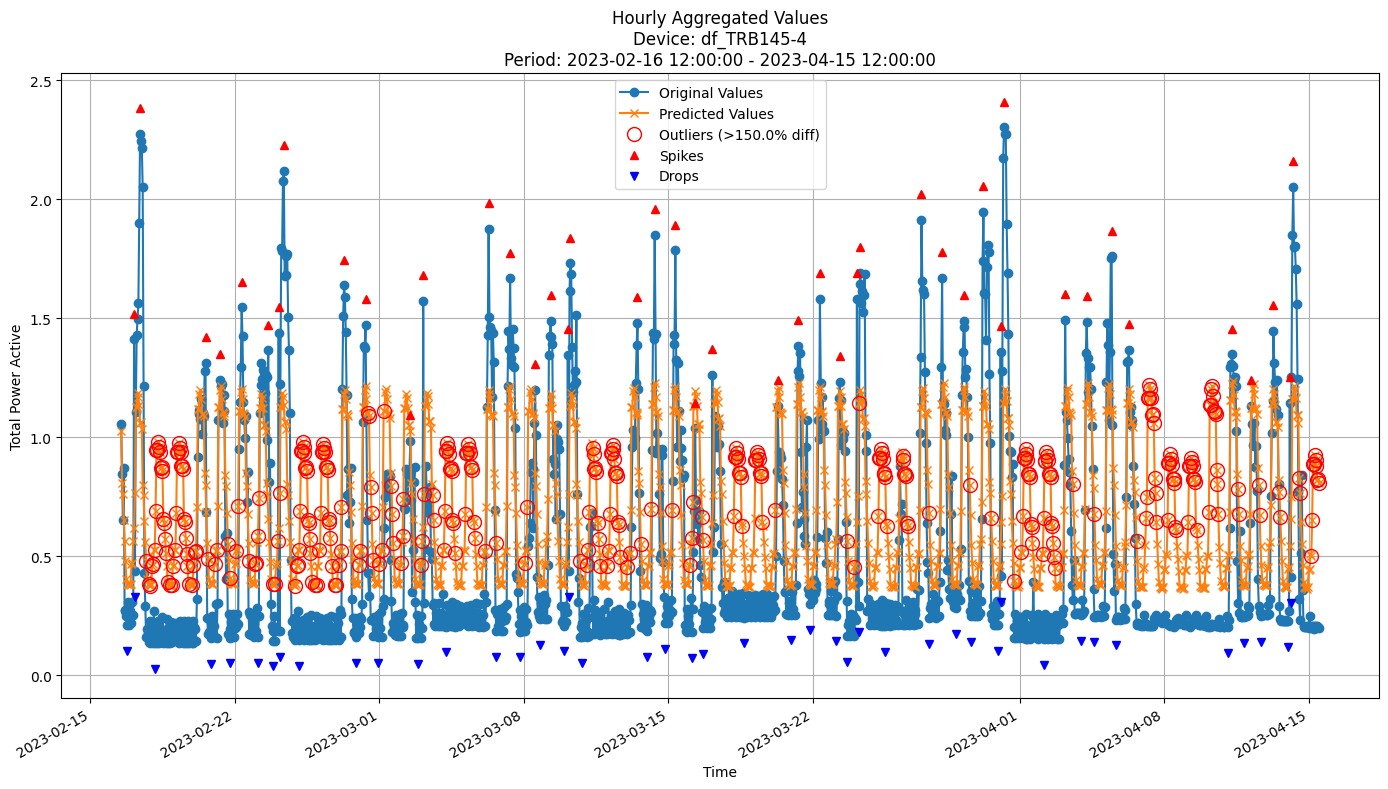


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.3725
MAE: 0.3034
MAPE: 106.9556%

Directional Metrics:
Directional Accuracy: 55.8908%
First-Diff Correlation: 0.4121

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [37]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in fodt_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, fodt_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, fodt_all_valid_preds[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### ARF (FastODT)

In [38]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

n_models = 20
grace_period = 0  # by default works for all leaves
aggregation_method = "mean"
split_confidence = 0.005
tau = 0.01
max_depth = 100
eagerness = 200

arf = ARFRegressorFODT(
        n_models=n_models,
        aggregation_method=aggregation_method,
        grace_period=grace_period,
        max_depth=max_depth,
        delta=split_confidence,
        tau=tau,
        seed=42,
        max_feature=0.7,
        eagerness=eagerness,
    )


In [39]:
arf_all_train_preds, arf_all_valid_preds, \
arf_all_train_metrics, arf_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model=arf,
    train=train,
    valid=valid,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    update_freq=update_freq,
    start_split=0,
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-10-22 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-10-22 13:00:00 - 2022-11-15 09:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.4830
	MAE: 0.3219
	MAPE: 37.0946%

Directional Metrics:
	Directional Accuracy: 54.8951%
	First-Diff Correlation: 0.3331

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 7.6178
	MAE: 6.4

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-11-15 09:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 10:00:00 - 2022-12-09 07:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.4940
	MAE: 0.3955
	MAPE: 81.8932%

Directional Metrics:
	Directional Accuracy: 62.4782%
	First-Diff Correlation: 0.4485

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 6.5226
	MAE: 5.2

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-03-12 08:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-03-12 09:00:00 - 2023-04-05 06:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3105
	MAE: 0.2465
	MAPE: 67.9170%

Directional Metrics:
	Directional Accuracy: 57.9407%
	First-Diff Correlation: 0.4036

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 3.8774
	MAE: 3.0

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-04-05 06:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-04-05 07:00:00 - 2023-04-15 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3103
	MAE: 0.2740
	MAPE: 101.6408%

Directional Metrics:
	Directional Accuracy: 55.5102%
	First-Diff Correlation: 0.4555

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 5.2297
	MAE: 4.

#### Results

In [40]:
print("\n\nTrain period metrics:")
arf_all_time_train_metrics = all_time_aggregation_metrics(arf_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
arf_all_time_valid_metrics = all_time_aggregation_metrics(arf_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.4337 ± 0.0383
	MAE: 0.3322 ± 0.0530
	MAPE: 75.1805% ± 18.6663%

	Directional Metrics:
		Directional Accuracy: 59.0917% ± 1.7242%
		First-Diff Correlation: 0.4078 ± 0.0681

	Immediate Detection (delta=0):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000
Daily Metrics:
	RMSE: 6.0386 ± 0.8297
	MAE: 4.4884 ± 0.8739
	MAPE: 43.0526% ± 10.8311%

	Directional Metrics:
		Directional Accuracy: 77.2089% ± 5.3011%
		First-Diff Correlation: 0.6951 ± 0.0894

	Immediate Detection (delta=0

#### Training plots


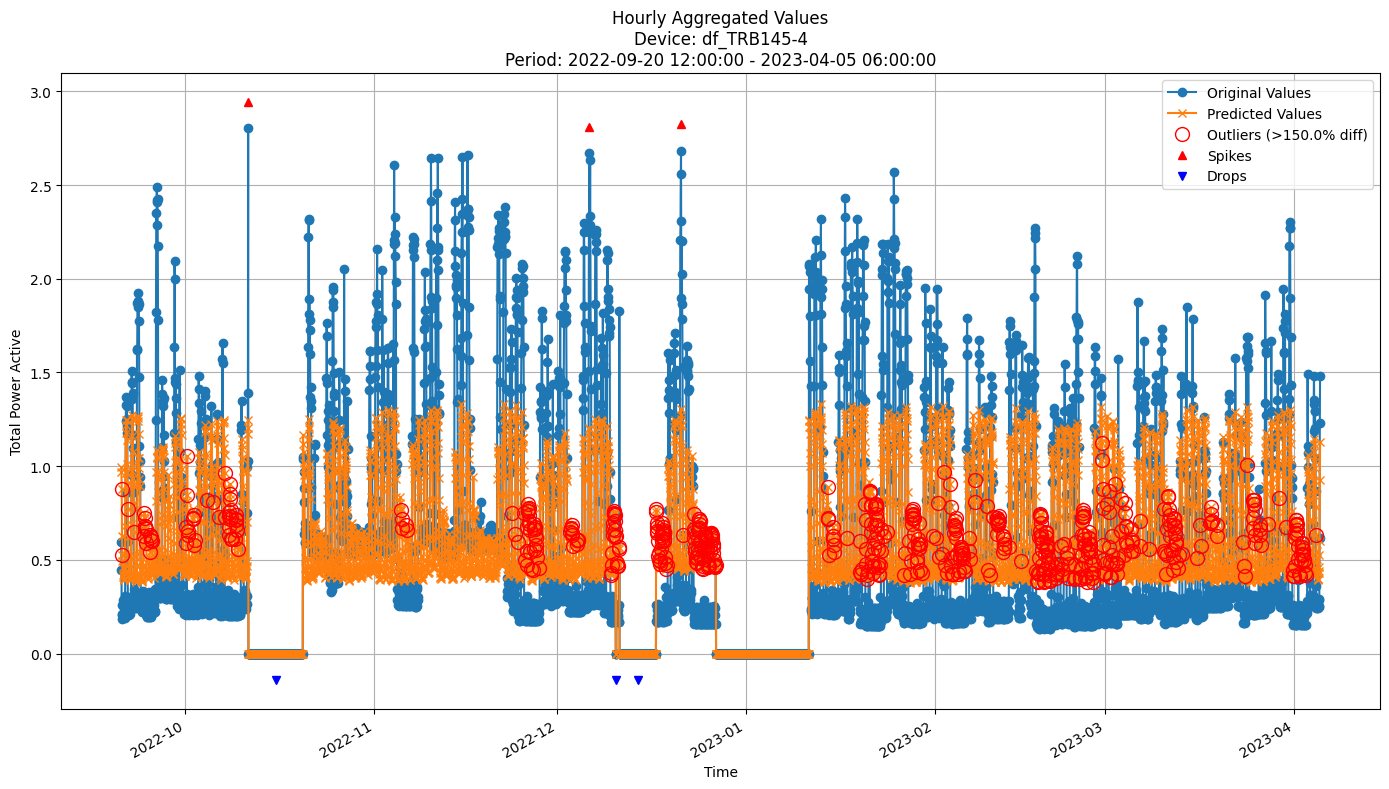


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.3947
MAE: 0.3075
MAPE: 77.4633%

Directional Metrics:
Directional Accuracy: 59.3891%
First-Diff Correlation: 0.4658

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [41]:
for device_id in arf_all_train_preds.keys():
    y_train = arf_all_train_preds[device_id][-1]['y_true']
    y_pred_train = arf_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

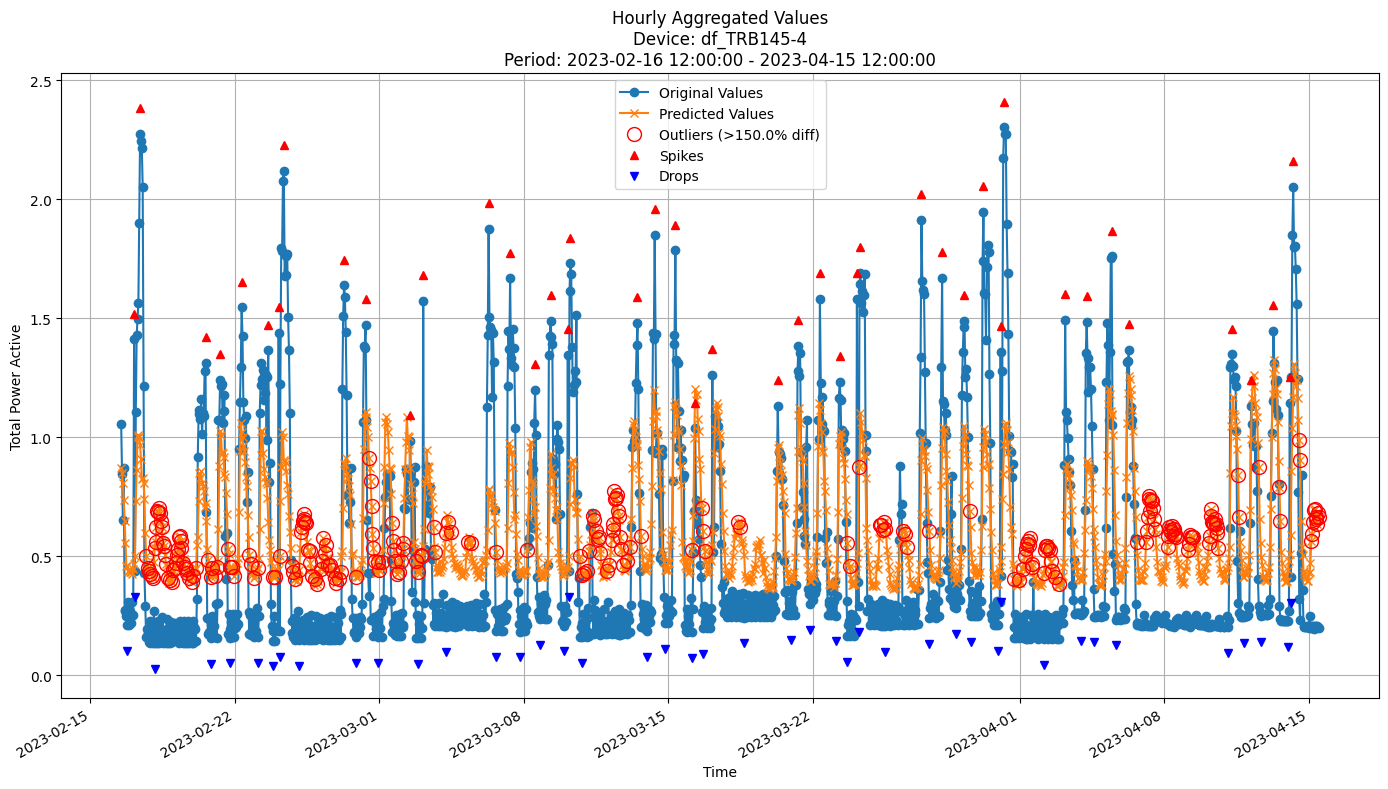


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.3339
MAE: 0.2764
MAPE: 87.2754%

Directional Metrics:
Directional Accuracy: 57.8305%
First-Diff Correlation: 0.3835

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [42]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in arf_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, arf_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, arf_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

### iNcubation Boost

In [43]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario:
split_confidence_hf = 0.01
n_trees = 100
grace_period = 0
depth = 50
eagerness = 1000
learning_rate = 0.5
max_features = 1.0
grace_period_depth = -1 # set to 1 to use only for first node, set to -1 to use for all nodes, set to N to use for N nodes
incb = IncubationBoost(
    fastodt.FastODT,
    length=n_trees,
    learning_rate=learning_rate,
    incubationMode = "DEFAULT",
    baseLearnerOptions = (depth, grace_period, split_confidence_hf, "hf", max_features, eagerness, grace_period_depth),
    verbose=False
    )


In [44]:
incb_all_train_preds, incb_all_valid_preds, \
incb_all_train_metrics, incb_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model=incb, 
    train=train, 
    valid=valid, 
    incremental=True, 
    data_freq=DATA_FREQUENCY,
    update_freq=update_freq, 
    start_split=0, 
    # end_split=1,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-10-22 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-10-22 13:00:00 - 2022-11-15 09:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.6997
	MAE: 0.5405
	MAPE: 57.5751%

Directional Metrics:
	Directional Accuracy: 52.4476%
	First-Diff Correlation: 0.2144

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 13.9303
	MAE: 12

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-11-15 09:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-11-15 10:00:00 - 2022-12-09 07:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.7084
	MAE: 0.4714
	MAPE: 45.2964%

Directional Metrics:
	Directional Accuracy: 54.2757%
	First-Diff Correlation: 0.3488

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 12.4660
	MAE: 10

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-03-12 08:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-03-12 09:00:00 - 2023-04-05 06:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3702
	MAE: 0.2279
	MAPE: 34.5714%

Directional Metrics:
	Directional Accuracy: 56.1955%
	First-Diff Correlation: 0.4267

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 6.0023
	MAE: 4.8

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-04-05 06:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-04-05 07:00:00 - 2023-04-15 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3211
	MAE: 0.2031
	MAPE: 44.0373%

Directional Metrics:
	Directional Accuracy: 51.4286%
	First-Diff Correlation: 0.3806

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 4.7321
	MAE: 3.9

#### Results

In [45]:
print("\n\nTrain period metrics:")
incb_all_time_train_metrics = all_time_aggregation_metrics(incb_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
incb_all_time_valid_metrics = all_time_aggregation_metrics(incb_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)
# Hourly Metrics:
# 	RMSE: 0.4348 ± 0.1387
# 	MAE: 0.3140 ± 0.0869
# 	MAPE: 60.2407% ± 12.6513%
# 	Dir Accuracy: 57.2071% ± 2.1944%
# 	First-Diff Correlation: 0.3343 ± 0.0699



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.5478 ± 0.0365
	MAE: 0.3629 ± 0.0363
	MAPE: 42.9093% ± 2.2990%

	Directional Metrics:
		Directional Accuracy: 59.2496% ± 7.8789%
		First-Diff Correlation: 0.5748 ± 0.0732

	Immediate Detection (delta=0):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.1429 ± 0.3499
		Spike Recall: 0.0032 ± 0.0078
		Spike F1: 0.0062 ± 0.0152
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000
Daily Metrics:
	RMSE: 9.2031 ± 1.0262
	MAE: 6.7077 ± 1.0671
	MAPE: 35.3664% ± 3.4977%

	Directional Metrics:
		Directional Accuracy: 84.8607% ± 4.8269%
		First-Diff Correlation: 0.8500 ± 0.0575

	Immediate Detection (delta=0):

#### Train plots

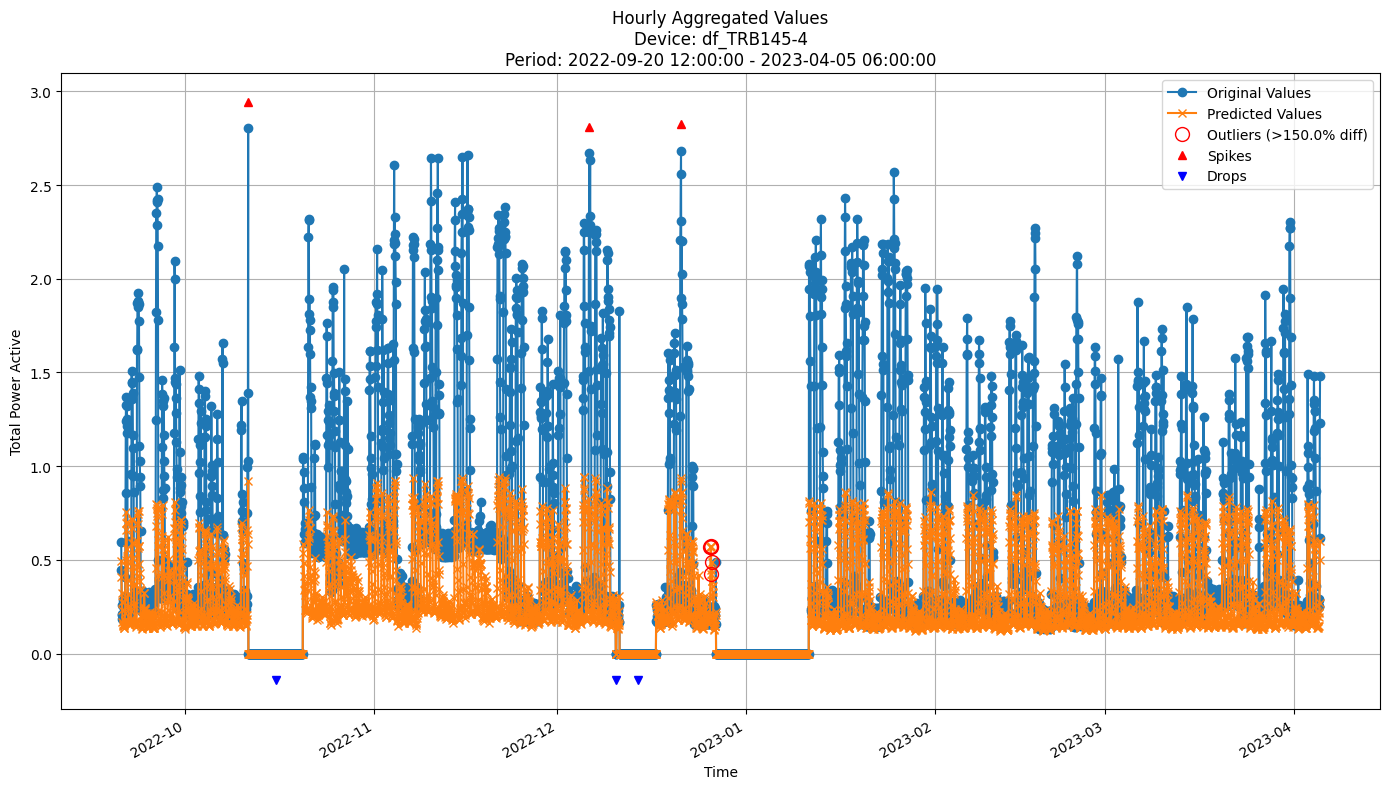


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.5040
MAE: 0.3239
MAPE: 39.4606%

Directional Metrics:
Directional Accuracy: 67.0506%
First-Diff Correlation: 0.6538

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 0.0222
  F1 Score: 0.0435
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [46]:
for device_id in incb_all_train_preds.keys():
    y_train = incb_all_train_preds[device_id][-1]['y_true']
    y_pred_train = incb_all_train_preds[device_id][-1]['y_pred']
    plot_hourly_predictions(y_train, 
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

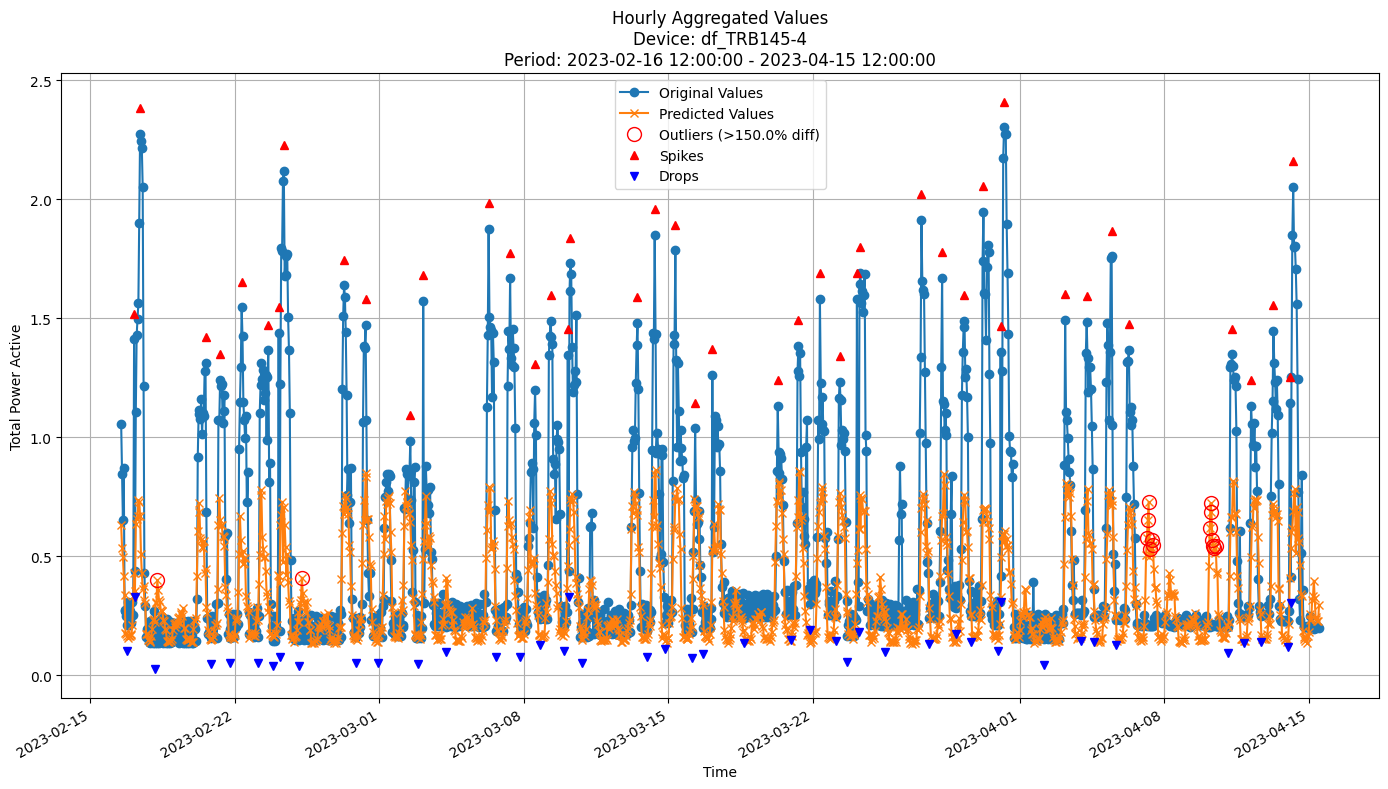


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.3729
MAE: 0.2238
MAPE: 36.2516%

Directional Metrics:
Directional Accuracy: 55.1724%
First-Diff Correlation: 0.3900

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [47]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in incb_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, incb_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, incb_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

# Test-set Model Evaluation
(`train[-1]` + `valid[-1]`) vs `test`

In [48]:
last_valid_dates = valid[-1][0][valid[-1][0][:, 1] == "df_TRB145-4"][:, 0]
test_dates = test[0][test[0][:, 1] == "df_TRB145-4"][:, 0]
print(f"Last validation set range: {last_valid_dates[0]} - {last_valid_dates[-1]}")
print(f"Test range: {test_dates[0]} - {test_dates[-1]}")
print(f"Test set length: {len(test_dates)}")

Last validation set range: 2023-04-05 07:00:00 - 2023-04-15 12:00:00
Test range: 2023-04-15 14:00:00 - 2023-05-30 18:00:00
Test set length: 1085


In [49]:
# Initialize the models beforehand to run this cell
models = [baseline, gbdt, rf, hoef, arf_hf, fodt, arf, incb]
model_test_results = {}
for model in models:
    if model in [gbdt, rf]:
        # Batch learning models
        incremental = False
        update_freq = "14D"
        print(f"Model: {model.__class__.__name__} - update_freq: {update_freq}")
    else:
        # Incremental learning models
        incremental = True
        update_freq = "1h"
        print(f"Model: {model.__class__.__name__} - update_freq: {update_freq}")

    _, test_preds, \
    _, test_metrics = test_set_seq_fit_predict(
        model=model, 
        train=train, 
        valid=valid,
        test=test,
        incremental=incremental, 
        data_freq=DATA_FREQUENCY,
        update_freq=update_freq,
        spike_prominence=1.,
        normalize_robust=False,
        predict_train=False,
        verbose=True
    )
    model_test_results[model.__class__.__name__] = {
        "test_preds": test_preds,
        "test_metrics": test_metrics
    }

Model: PreviousValueRegressor - update_freq: 1h


Processing devices for test predictions:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-04-15 12:00:00
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-04-15 14:00:00 - 2023-05-30 18:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2066
	MAE: 0.0944
	MAPE: 16.0510%

Directional Metrics:
	Directional Accuracy: 49.0775%
	First-Diff Correlation: 0.1927

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0319
	MAE: 0.0230
	MAPE: 0.1804%

Direction

Processing devices for test predictions:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 12:00:00 to 2023-04-15 12:00:00

Time: 10.77 seconds
Memory usage after retraining: 0.0000 MB
Predicting for chunk from 2023-04-15 14:00:00 to 2023-04-29 14:00:00

-------------------------

Retraining model on data from 2022-09-20 12:00:00 to 2023-04-29 14:00:00

Time: 11.31 seconds
Memory usage after retraining: 0.0000 MB
Predicting for chunk from 2023-04-29 15:00:00 to 2023-05-13 15:00:00

-------------------------

Retraining model on data from 2022-09-20 12:00:00 to 2023-05-13 15:00:00

Time: 12.44 seconds
Memory usage after retraining: 0.0000 MB
Predicting for chunk from 2023-05-13 16:00:00 to 2023-05-27 16:00:00

-------------------------

Retraining model on data from 2022-09-20 12:00:00 to 2023-05-27 16:00:00

Time: 13.77 seconds
Memory usage after retraining: 0.0000 MB
Predicting for chunk from 2023-05-27 17:00:00 to 2023-05-30 18:00:00

-------------------------
Metrics for Device: df_TRB145-4 | Period: 2023-04-15 14:00:00 - 2023-05-

Processing devices for test predictions:   0%|          | 0/1 [00:00<?, ?it/s]

... (7 outputs left out)

Processing devices for test predictions:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-04-15 12:00:00
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-04-15 14:00:00 - 2023-05-30 18:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3230
	MAE: 0.2414
	MAPE: 63.9092%

Directional Metrics:
	Directional Accuracy: 58.3948%
	First-Diff Correlation: 0.4631

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1389
		Recall: 0.1316
		F1: 0.1351
	Drops:
		Precision: 0.0571
		Recall: 0.0541
		F1: 0.0556

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.3611
		Recall: 0.3421
		F1: 0.3514
	Drops:
		Precision: 0.3143
		Recall: 0.2973
		F1: 0.3056
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 4.3937
	MAE: 3.5669
	MAPE: 41.0986%

Directio

Processing devices for test predictions:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-04-15 12:00:00
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-04-15 14:00:00 - 2023-05-30 18:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3859
	MAE: 0.2262
	MAPE: 36.0730%

Directional Metrics:
	Directional Accuracy: 59.7786%
	First-Diff Correlation: 0.4101

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1818
		Recall: 0.1579
		F1: 0.1690
	Drops:
		Precision: 0.1250
		Recall: 0.1081
		F1: 0.1159

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.5455
		Recall: 0.4737
		F1: 0.5070
	Drops:
		Precision: 0.1562
		Recall: 0.1351
		F1: 0.1449
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 6.4855
	MAE: 4.9319
	MAPE: 35.1804%

Directio

In [50]:
for model in models:
    model_test_results[model.__class__.__name__]['test_metrics'] = all_time_aggregation_metrics(
        model_test_results[model.__class__.__name__]['test_metrics'],
        data_freq=DATA_FREQUENCY,
        verbose=False)

# Model Comparison

In [51]:
AGG_LEVEL = "hourly"
METRICS = ["rmse", "mae", "mape", "dir_accuracy", "first_diff_corr"]
PERC_METRICS = ["mape", "dir_accuracy", "first_diff_corr"]
# SPIKES_METRICS = ["spikes_immediate.precision", "spikes_immediate.recall", "spikes_immediate.f1",
#                   "spikes_delayed.precision", "spikes_delayed.recall", "spikes_delayed.f1",
#                   "drops_immediate.precision", "drops_immediate.recall", "drops_immediate.f1",
#                   "drops_delayed.precision", "drops_delayed.recall", "drops_delayed.f1"]
SPIKES_METRICS = ["spikes_immediate.f1", "spikes_delayed.f1",
                  "drops_immediate.f1", "drops_delayed.f1"]

METRICS.extend(SPIKES_METRICS)
PERC_METRICS.extend(SPIKES_METRICS)

## Test results

In [52]:
MODEL_TEST_METRICS = {
    "Baseline": model_test_results[baseline.__class__.__name__]["test_metrics"],
    "GBDT": model_test_results[gbdt.__class__.__name__]["test_metrics"],
    "RandomForest": model_test_results[rf.__class__.__name__]["test_metrics"],
    "HoeffdingTree": model_test_results[hoef.__class__.__name__]["test_metrics"],
    "ARF_Hoeffding": model_test_results[arf_hf.__class__.__name__]["test_metrics"],
    "FastODT": model_test_results[fodt.__class__.__name__]["test_metrics"],
    "ARF_FastODT": model_test_results[arf.__class__.__name__]["test_metrics"],
    "IncubationBoost": model_test_results[incb.__class__.__name__]["test_metrics"],
}

In [53]:
device_ids = set()
for m in MODEL_TEST_METRICS.values():
    device_ids.update(m.keys())
device_ids = sorted(device_ids)

def format_metric(val, is_perc=False):
    if isinstance(val, dict) and "mean" in val and "std" in val:
        mean = val["mean"]
        std = val["std"]
        if is_perc:
            mean = mean * 100
            std = std * 100
        return f"{mean:.3f}"# ± {std:.3f}"
    if is_perc:
        return f"{val*100:.3f}" if val is not None else None
    return f"{val:.3f}" if val is not None else None

for device_id in device_ids:
    rows = []
    for model, mdict in MODEL_TEST_METRICS.items():
        if device_id in mdict and AGG_LEVEL in mdict[device_id]:
            vals = mdict[device_id][AGG_LEVEL]
            row = [model]
            for m in METRICS:
                is_perc = (m in PERC_METRICS)
                row.append(format_metric(vals.get(m, None), is_perc=is_perc))
            rows.append(row)
    df = pd.DataFrame(rows, columns=["Model", "RMSE", "MAE", "MAPE (%)", "Directional Accuracy (%)", "First Diff Corr (%)",
                                     "Spikes Immediate F1 (%)", "Spikes Delayed F1 (%)",
                                     "Drops Immediate F1 (%)", "Drops Delayed F1 (%)"])
    print(f"\nDevice: {device_id} | Aggregation: {AGG_LEVEL}")
    display(df)

    # RandomForest	0.223	0.129	26.880	57.166	40.782	10.127	48.101	2.597	15.584


Device: df_TRB145-4 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,Baseline,0.207,0.094,16.051,49.077,19.269,0.000,100.000,0.000,100.000
1,GBDT,0.215,0.127,25.716,55.443,40.986,14.085,50.704,2.899,14.493
2,RandomForest,0.227,0.131,26.976,56.181,38.744,2.899,28.986,2.985,26.866
3,HoeffdingTree,0.301,0.176,35.460,50.830,28.162,16.471,28.235,7.229,14.458
4,ARF_Hoeffding,0.266,0.157,31.417,54.059,38.952,5.797,52.174,5.970,20.896
5,FastODT,0.366,0.286,86.557,58.026,49.431,16.867,40.964,12.346,22.222
6,ARF_FastODT,0.323,0.241,63.909,58.395,46.306,13.514,35.135,5.556,30.556
7,IncubationBoost,0.386,0.226,36.073,59.779,41.012,16.901,50.704,11.594,14.493


## Validation results

In [54]:
MODEL_VALID_METRICS = {
    "Baseline": baseline_all_time_valid_metrics,
    "GBDT": gbdt_all_time_valid_metrics,
    "RandomForest": rf_all_time_valid_metrics,
    "HoeffdingTree": hoef_all_time_valid_metrics,
    "ARF_Hoeffding": arf_hf_all_time_valid_metrics,
    "FastODT": fodt_all_time_valid_metrics,
    "ARF_FastODT": arf_all_time_valid_metrics,
    "IncubationBoost": incb_all_time_valid_metrics,
}


device_ids = set()
for m in MODEL_VALID_METRICS.values():
    device_ids.update(m.keys())
device_ids = sorted(device_ids)

def format_metric(val, is_perc=False):
    if isinstance(val, dict) and "mean" in val and "std" in val:
        mean = val["mean"]
        std = val["std"]
        if is_perc:
            mean = mean * 100
            std = std * 100
        return f"{mean:.3f} ± {std:.3f}"
    if is_perc:
        return f"{val*100:.3f}" if val is not None else None
    return f"{val:.3f}" if val is not None else None

for device_id in device_ids:
    rows = []
    for model, mdict in MODEL_VALID_METRICS.items():
        if device_id in mdict and AGG_LEVEL in mdict[device_id]:
            vals = mdict[device_id][AGG_LEVEL]
            row = [model]
            for m in METRICS:
                is_perc = (m in PERC_METRICS)
                row.append(format_metric(vals.get(m, None), is_perc=is_perc))
            rows.append(row)
    df = pd.DataFrame(rows, columns=["Model", "RMSE", "MAE", "MAPE (%)", "Directional Accuracy (%)", "First Diff Corr (%)",
                                     "Spikes Immediate F1 (%)", "Spikes Delayed F1 (%)", "Drops Immediate F1 (%)", "Drops Delayed F1 (%)"])
    print(f"\nDevice: {device_id} | Aggregation: {AGG_LEVEL}")
    display(df)


Device: df_TRB145-4 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,Baseline,0.245 ± 0.028,0.138 ± 0.022,26.419 ± 7.054,36.931 ± 3.102,9.734 ± 13.688,0.000 ± 0.000,85.714 ± 34.993,0.000 ± 0.000,85.714 ± 34.993
1,GBDT,0.251 ± 0.045,0.163 ± 0.037,34.722 ± 7.447,60.026 ± 5.281,38.378 ± 7.677,7.215 ± 7.304,26.758 ± 18.780,8.790 ± 8.683,10.470 ± 10.594
2,RandomForest,0.115 ± 0.011,0.071 ± 0.007,13.096 ± 1.795,78.933 ± 2.479,88.327 ± 2.579,15.081 ± 18.839,23.803 ± 30.041,7.162 ± 8.795,7.533 ± 9.293
3,HoeffdingTree,0.336 ± 0.047,0.212 ± 0.036,40.727 ± 6.967,50.791 ± 4.717,26.805 ± 8.182,0.000 ± 0.000,17.948 ± 16.785,1.786 ± 4.374,9.389 ± 8.375
4,ARF_Hoeffding,0.281 ± 0.043,0.195 ± 0.031,44.679 ± 7.578,55.724 ± 3.456,40.973 ± 8.841,6.640 ± 6.464,24.457 ± 20.748,6.720 ± 6.814,13.616 ± 11.811
5,FastODT,0.460 ± 0.088,0.360 ± 0.059,97.402 ± 30.215,55.274 ± 2.104,38.418 ± 12.369,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000
6,ARF_FastODT,0.411 ± 0.079,0.339 ± 0.070,96.869 ± 38.113,58.609 ± 2.518,43.676 ± 7.229,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000
7,IncubationBoost,0.513 ± 0.149,0.333 ± 0.121,42.502 ± 7.385,55.431 ± 2.947,37.431 ± 7.497,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000


### By-period validation results

In [55]:
MODEL_VALID_PERIOD_METRICS = {
    "Baseline": baseline_valid_period_metrics,
    "GBDT": gbdt_valid_period_metrics,
    "RandomForest": rf_valid_period_metrics,
    "HoeffdingTree": hoef_all_valid_metrics,
    "ARF_Hoeffding": arf_hf_all_valid_metrics,
    "FastODT": fodt_all_valid_metrics,
    "ARF_FastODT": arf_all_valid_metrics,
    "IncubationBoost": incb_all_valid_metrics,
}

def show_per_period_metric_tables(device_ids, MODEL_VALID_PERIOD_METRICS, AGG_LEVEL, metric_name, display_gain=True):
    """
    Display per-period metric tables and gain/drop tables for a given metric.
    Args:
        device_ids: List of device IDs to display metrics for.
        MODEL_VALID_PERIOD_METRICS: Dictionary containing model period metrics.
        AGG_LEVEL: Aggregation level (e.g., "hourly").
        metric_name: The name of the metric to display.
        display_gain: Whether to display gain/drop tables.
    """
    for device_id in device_ids:
        period_vals = {}
        n_periods = None
        for model, mdict in MODEL_VALID_PERIOD_METRICS.items():
                if metric_name in PERC_METRICS:
                    vals = [period[AGG_LEVEL][metric_name]*100 for period in mdict[device_id]]
                    period_vals[model] = [f"{v:.3f}" for v in vals]
                else:
                    vals = [period[AGG_LEVEL][metric_name] for period in mdict[device_id]]
                    period_vals[model] = [f"{v:.3f}" for v in vals]
                n_periods = len(vals)
        if not period_vals:
            continue

        df_metric = pd.DataFrame(period_vals)
        df_metric.index = [f"Period {i+1}" for i in range(n_periods)]
        df_metric['Agg. Per Period'] = df_metric.astype(float).mean(axis=1)

        metric_label = f"{metric_name.upper()} (%)" if metric_name in PERC_METRICS else metric_name.upper()
        print(f"\nDevice: {device_id} | Aggregation: {AGG_LEVEL} | {metric_label} per period")
        display(df_metric)


        if display_gain:
            # Absolute gain/drop
            abs_gain = df_metric.astype(float).diff().iloc[1:]
            abs_gain = abs_gain.applymap(lambda v: f"{v:.3f}")
            abs_gain.index = [f"{df_metric.index[i]} - {df_metric.index[i-1]}" for i in range(1, len(df_metric))]
            print(f"\nAbsolute gain/drop in {metric_label}:")
            display(abs_gain)
            # Percentage gain/drop
            # pct_gain = df_metric.astype(float).pct_change().iloc[1:] * 100
            # pct_gain = pct_gain.applymap(lambda v: f"{v:.3f}")
            # pct_gain.index = abs_gain.index
            # print(f"\nPercentage gain/drop in {metric_label} (lower is better):")
            # display(pct_gain)

#### Directional accuracy (higher is better)


In [56]:
# MAPE per period and gain/drop
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="dir_accuracy",
    display_gain=True
)


Device: df_TRB145-4 | Aggregation: hourly | DIR_ACCURACY (%) per period


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,33.042,57.517,59.965,47.552,49.825,50.874,54.895,52.448,50.764750
Period 2,37.871,54.974,52.705,50.262,56.545,54.625,62.478,54.276,52.967000
Period 3,35.664,65.559,59.091,50.175,56.469,57.517,60.315,56.818,55.201000
Period 4,36.300,67.190,66.492,56.894,60.035,56.894,60.209,61.082,58.137000
Period 5,34.965,64.685,63.287,57.517,59.441,55.245,58.916,55.769,56.228125
Period 6,36.998,52.705,52.880,42.932,51.832,57.068,57.941,56.195,51.068875
Period 7,43.673,57.551,60.000,50.204,55.918,54.694,55.510,51.429,53.622375



Absolute gain/drop in DIR_ACCURACY (%):


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,4.829,-2.543,-7.260,2.710,6.720,3.751,7.583,1.828,2.202
Period 3 - Period 2,-2.207,10.585,6.386,-0.087,-0.076,2.892,-2.163,2.542,2.234
Period 4 - Period 3,0.636,1.631,7.401,6.719,3.566,-0.623,-0.106,4.264,2.936
Period 5 - Period 4,-1.335,-2.505,-3.205,0.623,-0.594,-1.649,-1.293,-5.313,-1.909
Period 6 - Period 5,2.033,-11.980,-10.407,-14.585,-7.609,1.823,-0.975,0.426,-5.159
Period 7 - Period 6,6.675,4.846,7.120,7.272,4.086,-2.374,-2.431,-4.766,2.554


#### MAPE (lower is better)

In [57]:
# MAPE per period and gain/drop
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="mape",
    display_gain=True
)


Device: df_TRB145-4 | Aggregation: hourly | MAPE (%) per period


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,17.963,28.054,21.298,27.444,31.806,42.916,37.095,57.575,33.018875
Period 2,24.007,34.890,30.172,39.938,45.505,73.404,81.893,45.296,46.888125
Period 3,32.582,50.750,47.943,52.114,54.512,131.830,166.383,43.234,72.418500
Period 4,30.139,32.854,34.975,36.845,42.922,101.088,122.652,38.206,54.960125
Period 5,35.590,38.572,38.980,44.459,55.149,121.204,100.500,34.592,58.630750
Period 6,29.454,30.029,31.633,42.230,39.840,83.968,67.917,34.571,44.955250
Period 7,15.200,27.906,24.470,42.058,43.020,127.405,101.641,44.037,53.217125



Absolute gain/drop in MAPE (%):


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,6.044,6.836,8.874,12.494,13.699,30.488,44.798,-12.279,13.869
Period 3 - Period 2,8.575,15.860,17.771,12.176,9.007,58.426,84.490,-2.062,25.530
Period 4 - Period 3,-2.443,-17.896,-12.968,-15.269,-11.590,-30.742,-43.731,-5.028,-17.458
Period 5 - Period 4,5.451,5.718,4.005,7.614,12.227,20.116,-22.152,-3.614,3.671
Period 6 - Period 5,-6.136,-8.543,-7.347,-2.229,-15.309,-37.236,-32.583,-0.021,-13.675
Period 7 - Period 6,-14.254,-2.123,-7.163,-0.172,3.180,43.437,33.724,9.466,8.262


#### RMSE (lower is better)

In [58]:
# RMSE per period and gain/drop
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="rmse",
    display_gain=True
)


Device: df_TRB145-4 | Aggregation: hourly | RMSE per period


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,0.260,0.316,0.279,0.398,0.341,0.538,0.483,0.700,0.414375
Period 2,0.267,0.302,0.301,0.403,0.344,0.582,0.494,0.708,0.425125
Period 3,0.271,0.278,0.265,0.362,0.262,0.550,0.507,0.612,0.388375
Period 4,0.246,0.225,0.252,0.288,0.269,0.413,0.405,0.487,0.323125
Period 5,0.251,0.232,0.252,0.297,0.287,0.389,0.365,0.396,0.308625
Period 6,0.237,0.218,0.230,0.320,0.248,0.338,0.310,0.370,0.283875
Period 7,0.182,0.185,0.179,0.284,0.219,0.407,0.310,0.321,0.260875



Absolute gain/drop in RMSE:


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,0.007,-0.014,0.022,0.005,0.003,0.044,0.011,0.008,0.011
Period 3 - Period 2,0.004,-0.024,-0.036,-0.041,-0.082,-0.032,0.013,-0.096,-0.037
Period 4 - Period 3,-0.025,-0.053,-0.013,-0.074,0.007,-0.137,-0.102,-0.125,-0.065
Period 5 - Period 4,0.005,0.007,0.000,0.009,0.018,-0.024,-0.040,-0.091,-0.015
Period 6 - Period 5,-0.014,-0.014,-0.022,0.023,-0.039,-0.051,-0.055,-0.026,-0.025
Period 7 - Period 6,-0.055,-0.033,-0.051,-0.036,-0.029,0.069,0.000,-0.049,-0.023
